Training & Validasi R‑CNN (BOUNDING BOX)

In [1]:
import os, json, random, time
import numpy as np
import torch
import cv2 
from pathlib import Path
from collections import defaultdict, Counter
import torchvision
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision.transforms import functional as TF
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from pycocotools.coco import COCO
from torchinfo import summary
from tqdm import tqdm
import seaborn as sns

# SEED UNTUK REPRODUCIBILITY
SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# CONFIG PATHS DATASET
BASE_DIR = Path("Tanggul/eksperimen/dataset/augmentasi_bbox")
SPLITS = {
    "train": BASE_DIR / "train",
    "valid": BASE_DIR / "valid",
    "test":  BASE_DIR / "test",
}
ANNOT_FILES = {
    "train": SPLITS["train"] / "train_annotations.coco.json",
    "valid": SPLITS["valid"] / "valid_annotations.coco.json",
    "test":  SPLITS["test"]  / "test_annotations.coco.json",
}

# Pastikan file JSON dan Folder ada
for name, p in ANNOT_FILES.items():
    assert p.exists(), f"Annotation file missing: {name} -> {p}"
for name, d in SPLITS.items():
    assert d.exists(), f"Image dir missing: {name} -> {d}"

# DEFINISI KELAS & WARNA (MERAH, HIJAU, BIRU)
FINAL_CLASS_NAMES = ["Retak-Berat", "Retak-Ringan", "Tidak-Retak"]
# Background = 0, kelas mulai dari 1
FINAL_NAME_TO_ID = {n: i+1 for i, n in enumerate(FINAL_CLASS_NAMES)}  
FINAL_ID_TO_NAME = {v: k for k, v in FINAL_NAME_TO_ID.items()}
NUM_CLASSES      = len(FINAL_CLASS_NAMES) + 1 # +1 untuk Background

# Warna Visualisasi (Format RGB)
CLASS_COLORS = {
    1: (255, 0, 0),    # Retak-Berat  -> Merah
    2: (0, 255, 0),    # Retak-Ringan -> Hijau
    3: (0, 0, 255)     # Tidak-Retak  -> Biru
}

print("FINAL_CLASS_NAMES:", FINAL_CLASS_NAMES)
print("NUM_CLASSES:", NUM_CLASSES)

# CONFIG UTILS
TARGET_SIZE = (256, 256)
OUT_DIR = Path("Result_Object_Detection")
(OUT_DIR / "checkpoints").mkdir(parents=True, exist_ok=True)
(OUT_DIR / "viz").mkdir(parents=True, exist_ok=True)

# DataLoader config
NUM_WORKERS = 0 
PIN_MEMORY  = True if torch.cuda.is_available() else False

Device: cuda
FINAL_CLASS_NAMES: ['Retak-Berat', 'Retak-Ringan', 'Tidak-Retak']
NUM_CLASSES: 4


Dataset Class & Cache Anotasi

In [2]:
def remap_category_id(coco: COCO, cat_id: int) -> int:
    try:
        cat = coco.loadCats([cat_id])[0]
        name = cat["name"].strip()
        return FINAL_NAME_TO_ID.get(name, 0) # Return 0 jika tidak ditemukan
    except:
        return 0

# FUNGSI INDEXING UNTUK SAMPLER
def build_annotation_index(coco: COCO, img_ids):
    img_to_labels = defaultdict(list)
    
    for img_id in img_ids:
        ann_ids = coco.getAnnIds(imgIds=img_id)
        anns = coco.loadAnns(ann_ids)
        
        if len(anns) == 0:
            # Jika tidak ada anotasi, catat sebagai Tidak-Retak
            img_to_labels[img_id].append(FINAL_NAME_TO_ID["Tidak-Retak"])
        else:
            for ann in anns:
                lid = remap_category_id(coco, ann["category_id"])
                if lid != 0: 
                    img_to_labels[img_id].append(lid)
                    
    return img_to_labels, None # Kita hanya butuh label untuk sampler

# CLASS DATASET UTAMA
class CocoDetectionDataset(Dataset):
    def __init__(self, img_dir: Path, ann_path: Path, target_size=(256, 256)):
        self.img_dir = Path(img_dir)
        self.coco = COCO(str(ann_path))
        # Pastikan img_ids urut agar konsisten
        self.img_ids = list(sorted(self.coco.imgs.keys())) 
        self.target_size = target_size
        
        # Cache placeholder
        self.cached_labels = None 

    def __len__(self):
        return len(self.img_ids)

    def _load_image(self, img_id):
        info = self.coco.loadImgs(img_id)[0]
        path = self.img_dir / info["file_name"]
        
        img = Image.open(path).convert("RGB")
        # Resize gambar
        img = img.resize((self.target_size[1], self.target_size[0]), Image.BILINEAR)
        return TF.to_tensor(img)

    def _load_targets(self, img_id):
        # Ambil anotasi langsung dari COCO (aman & akurat)
        ann_ids = self.coco.getAnnIds(imgIds=img_id)
        anns = self.coco.loadAnns(ann_ids)
        
        info = self.coco.loadImgs(img_id)[0]
        w0, h0 = info["width"], info["height"]
        
        # Scaling factor
        sx, sy = self.target_size[1] / w0, self.target_size[0] / h0

        boxes, labels, areas, iscrowd = [], [], [], []
        
        for ann in anns:
            x, y, w, h = ann["bbox"]
            
            # Remap ID
            cat_id = remap_category_id(self.coco, ann["category_id"])
            if cat_id == 0: continue # Skip background internal/invalid
            
            # Resize Bbox
            x1, y1 = x * sx, y * sy
            x2, y2 = (x + w) * sx, (y + h) * sy
            
            # Validasi koordinat
            x2 = max(x2, x1 + 1)
            y2 = max(y2, y1 + 1)
            
            boxes.append([x1, y1, x2, y2])
            labels.append(cat_id)
            areas.append(ann.get("area", w*h) * sx * sy)
            iscrowd.append(ann.get("iscrowd", 0))

        # LOGIKA PENTING: HANDLING TIDAK-RETAK
        if len(boxes) == 0:
            
            boxes = [[0.0, 0.0, float(self.target_size[1]), float(self.target_size[0])]]
            labels = [FINAL_NAME_TO_ID["Tidak-Retak"]]
            areas = [float(self.target_size[1] * self.target_size[0])]
            iscrowd = [0]
            
        # Convert ke Tensor
        target = {
            "boxes":    torch.tensor(boxes, dtype=torch.float32),
            "labels":   torch.tensor(labels, dtype=torch.int64),
            "image_id": torch.tensor([img_id], dtype=torch.int64),
            "area":     torch.tensor(areas, dtype=torch.float32),
            "iscrowd":  torch.tensor(iscrowd, dtype=torch.int64),
        }
        return target

    def __getitem__(self, idx):
        img_id = self.img_ids[idx]
        img = self._load_image(img_id)
        target = self._load_targets(img_id)
        return img, target

# Wajib untuk DataLoader Object Detection
def collate_fn(batch):
    return tuple(zip(*batch))

# INSTANSIASI DATASET
print("Memuat Dataset")
train_ds = CocoDetectionDataset(SPLITS["train"], ANNOT_FILES["train"], TARGET_SIZE)
valid_ds = CocoDetectionDataset(SPLITS["valid"], ANNOT_FILES["valid"], TARGET_SIZE)
test_ds  = CocoDetectionDataset(SPLITS["test"],  ANNOT_FILES["test"],  TARGET_SIZE)

# BUILD INDEX UNTUK SAMPLER (PENTING UNTUK IMBALANCE)
print("Membangun Index untuk Sampler")
train_labels_idx, _ = build_annotation_index(train_ds.coco, train_ds.img_ids)

# Attach ke dataset object agar bisa dibaca 
train_ds.cached_labels = train_labels_idx

Memuat Dataset
loading annotations into memory...
Done (t=0.05s)
creating index...
index created!
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Membangun Index untuk Sampler


Distribusi & Sampler

In [3]:
valid_labels_idx, _ = build_annotation_index(valid_ds.coco, valid_ds.img_ids)
test_labels_idx, _  = build_annotation_index(test_ds.coco,  test_ds.img_ids)

# Pastikan Train index
if train_ds.cached_labels:
    train_labels_idx = train_ds.cached_labels
else:
    train_labels_idx, _ = build_annotation_index(train_ds.coco, train_ds.img_ids)

# FUNGSI DISTRIBUSI & PRINT STATISTIK
def image_level_distribution(img_ids, labels_index):
    counts = np.zeros(NUM_CLASSES, dtype=int)
    for img_id in img_ids:
        # Ambil label unik di gambar tsb (agar 1 gambar dihitung 1x per kelasnya)
        present_labels = set(labels_index.get(img_id, []))
        if len(present_labels) == 0:
            # Fallback jika kosong -> Tidak-Retak
            present_labels = {FINAL_NAME_TO_ID["Tidak-Retak"]}
            
        for lid in present_labels:
            if lid < NUM_CLASSES: # Safety check
                counts[lid] += 1
    return counts

# Hitung distribusi
train_counts = image_level_distribution(train_ds.img_ids, train_labels_idx)
valid_counts = image_level_distribution(valid_ds.img_ids, valid_labels_idx)
test_counts  = image_level_distribution(test_ds.img_ids,  test_labels_idx)

# Format ke Dictionary (Skip Background ID 0 untuk display)
def format_dist(counts):
    return {FINAL_ID_TO_NAME[i]: int(c) for i, c in enumerate(counts) if i != 0}

train_dist = format_dist(train_counts)
valid_dist = format_dist(valid_counts)
test_dist  = format_dist(test_counts)

print(f"\nDistribusi Train: {train_dist} | Total Img: {len(train_ds)}")
print(f"Distribusi Valid: {valid_dist} | Total Img: {len(valid_ds)}")
print(f"Distribusi Test : {test_dist}  | Total Img: {len(test_ds)}")

# BUILD SAMPLER (IMAGE LEVEL)
def build_image_sampler(img_ids, labels_index, class_counts):
    # Hitung bobot per kelas (Inverse Frequency)
    # Tambah 1e-6 untuk menghindari devision by zero
    c_counts = class_counts.astype(float)
    c_counts[c_counts == 0] = 1.0 
    class_weights = 1.0 / c_counts
    
    sample_weights = []
    for img_id in img_ids:
        # Ambil label yang ada di gambar
        present = labels_index.get(img_id, [])
        if not present:
            present = [FINAL_NAME_TO_ID["Tidak-Retak"]]
        
        # Strategi: Ambil bobot TERBESAR (kelas paling langka/minoritas) di gambar tersebut
        # Ini memaksa model melihat gambar yang ada "Retak-Berat" lebih sering
        w = max(class_weights[lid] for lid in present)
        sample_weights.append(float(w))
        
    # Buat Sampler
    return WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)

print("\nMembuat WeightedRandomSampler untuk Training")
train_sampler = build_image_sampler(train_ds.img_ids, train_labels_idx, train_counts)

# DATALOADERS
def collate_fn(batch):
    images, targets = zip(*batch)
    return list(images), list(targets)

# SETTING BATCH SIZE
# Disarankan 4 agar lebih cepat. Jika GPU OOM, ubah ke 2.
BATCH_SIZE = 4 

print(f"Inisialisasi DataLoader (Batch Size: {BATCH_SIZE})")

# Sampler hanya untuk TRAIN. Valid/Test pakai Shuffle=False
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=train_sampler, 
                          collate_fn=collate_fn, num_workers=0, pin_memory=PIN_MEMORY)

valid_loader = DataLoader(valid_ds, batch_size=BATCH_SIZE, shuffle=False, 
                          collate_fn=collate_fn, num_workers=0, pin_memory=PIN_MEMORY)

test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, 
                          collate_fn=collate_fn, num_workers=0, pin_memory=PIN_MEMORY)


Distribusi Train: {'Retak-Berat': 1149, 'Retak-Ringan': 1383, 'Tidak-Retak': 1668} | Total Img: 4200
Distribusi Valid: {'Retak-Berat': 551, 'Retak-Ringan': 563, 'Tidak-Retak': 686} | Total Img: 1800
Distribusi Test : {'Retak-Berat': 32, 'Retak-Ringan': 30, 'Tidak-Retak': 28}  | Total Img: 90

Membuat WeightedRandomSampler untuk Training
Inisialisasi DataLoader (Batch Size: 4)


Visualisasi Bar Chart

Grafik distribusi disimpan di: Result_Object_Detection\viz\dataset_distribution.png


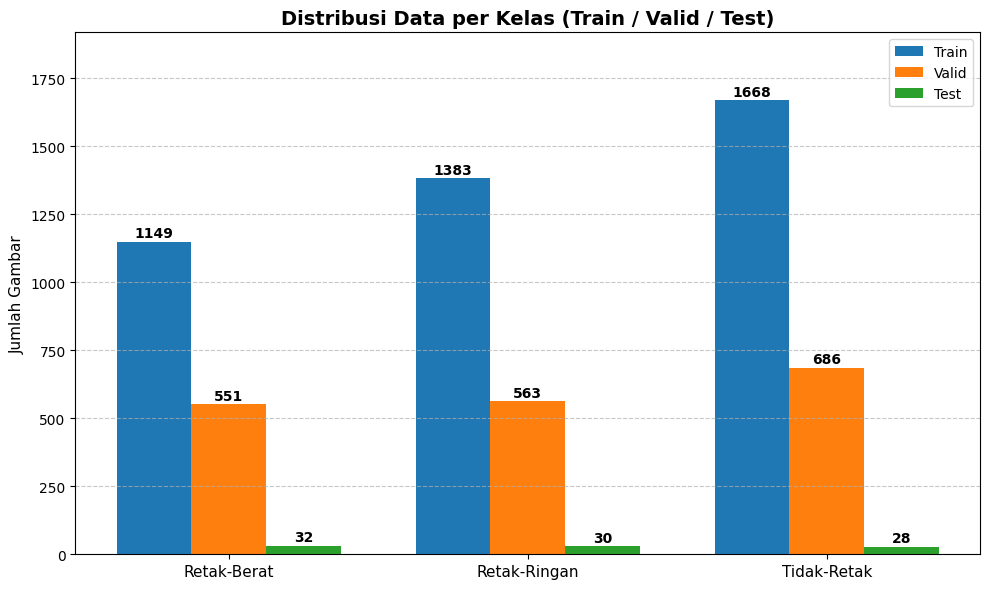

In [4]:
labels = FINAL_CLASS_NAMES  # ['Retak-Berat', 'Retak-Ringan', 'Tidak-Retak']

# Mengambil nilai count dari numpy array
train_vals = [int(train_counts[FINAL_NAME_TO_ID[n]]) for n in labels]
valid_vals = [int(valid_counts[FINAL_NAME_TO_ID[n]]) for n in labels]
test_vals  = [int(test_counts[FINAL_NAME_TO_ID[n]])  for n in labels]

x = np.arange(len(labels))  # Lokasi label di sumbu X
width = 0.25                # Lebar batang

plt.figure(figsize=(10, 6))

# Plot Bar untuk Train, Valid, Test
bar1 = plt.bar(x - width, train_vals, width, label="Train", color="#1f77b4") # Biru
bar2 = plt.bar(x,         valid_vals, width, label="Valid", color="#ff7f0e") # Oranye
bar3 = plt.bar(x + width, test_vals,  width, label="Test",  color="#2ca02c") # Hijau

# Fungsi bantu untuk menambah label teks di atas bar
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        plt.text(rect.get_x() + rect.get_width()/2., height + 5,
                 f'{height}',
                 ha='center', va='bottom', fontsize=10, fontweight='bold')

autolabel(bar1)
autolabel(bar2)
autolabel(bar3)

# Formatting Grafik
plt.xticks(x, labels, fontsize=11)
plt.ylabel("Jumlah Gambar", fontsize=11)
plt.title("Distribusi Data per Kelas (Train / Valid / Test)", fontsize=14, fontweight='bold')
plt.legend()
plt.ylim(0, max(train_vals + valid_vals + test_vals) * 1.15) # Beri ruang kosong 15% di atas
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# Simpan dan Tampilkan
save_path = OUT_DIR / "viz" / "dataset_distribution.png"
plt.savefig(save_path)
print(f"Grafik distribusi disimpan di: {save_path}")
plt.show()

Visualisasi Dataset

Menyiapkan visualisasi 3 sampel per kelas


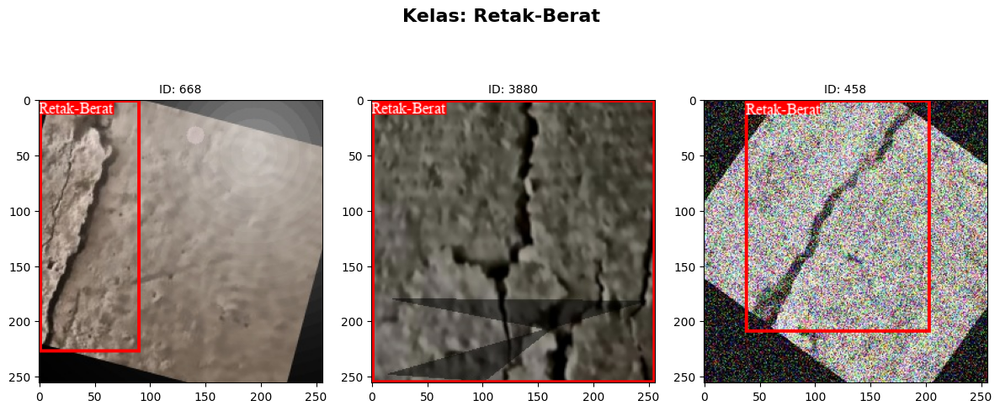

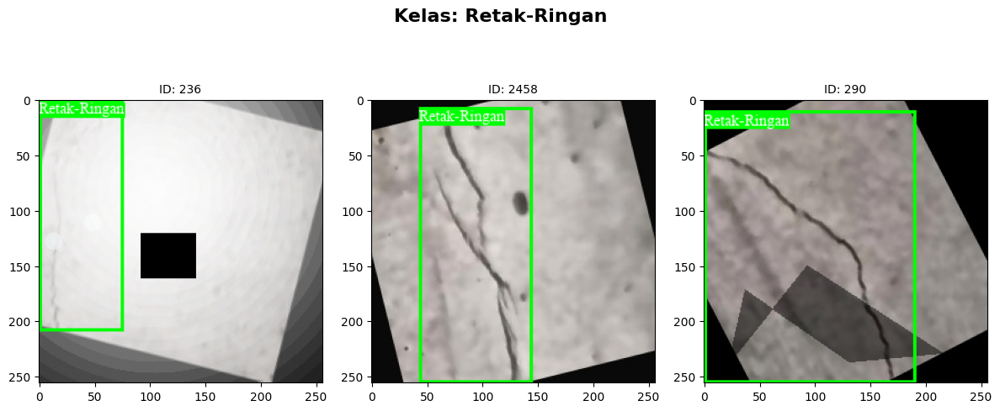

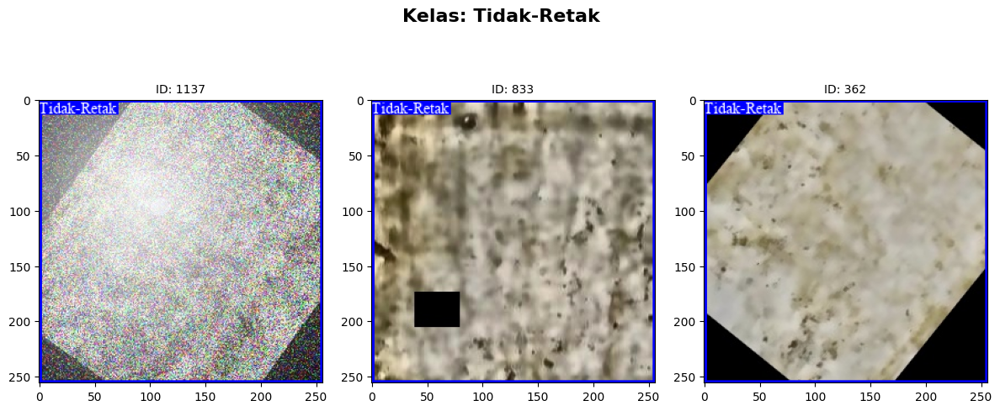

In [5]:
FONT_PATH = "C:/Windows/Fonts/times.ttf" 
FONT_SIZE = 14

try:
    font = ImageFont.truetype(FONT_PATH, FONT_SIZE)
except Exception:
    # Fallback jika font tidak ditemukan
    font = ImageFont.load_default()

# Mengambil warna dari CLASS_COLORS
LABEL_COLORS_PIL = {k: v for k, v in CLASS_COLORS.items()}

# FUNGSI VISUALISASI GRID PER KELAS
def visualize_grid_per_class(dataset, samples_per_class=3):
    print(f"Menyiapkan visualisasi {samples_per_class} sampel per kelas")
    
    # Kumpulkan ID gambar untuk setiap kelas
    class_to_imgs = {cls_id: [] for cls_id in FINAL_NAME_TO_ID.values()}
    
    # Scan dataset secara acak agar variatif (shuffle index)
    indices = list(range(len(dataset)))
    random.shuffle(indices)
    
    for idx in indices:
        img_id = dataset.img_ids[idx]
        
        # Cek label apa saja yang ada 
        if hasattr(dataset, 'cached_labels') and dataset.cached_labels:
            labels_in_img = dataset.cached_labels.get(img_id, [])
        else:
            # Fallback manual load jika cache belum ada
            ann_ids = dataset.coco.getAnnIds(imgIds=img_id)
            anns = dataset.coco.loadAnns(ann_ids)
            if not anns: labels_in_img = [FINAL_NAME_TO_ID["Tidak-Retak"]]
            else: labels_in_img = [remap_category_id(dataset.coco, a['category_id']) for a in anns]

        # Ambil label unik di gambar
        unique_labels = set(labels_in_img)
        
        # Masukkan gambar ini ke slot kelas yang belum penuh
        for lid in unique_labels:
            if lid in class_to_imgs and len(class_to_imgs[lid]) < samples_per_class:
                class_to_imgs[lid].append(img_id)
        
        # Cek apakah semua kelas sudah cukup sampel
        if all(len(v) >= samples_per_class for v in class_to_imgs.values()):
            break

    # MULAI PLOTTING
    for label_id, img_ids in class_to_imgs.items():
        if len(img_ids) == 0:
            continue
            
        class_name = FINAL_ID_TO_NAME.get(label_id, str(label_id))
        
        # Setup Figure
        fig, axes = plt.subplots(1, max(1, len(img_ids)), figsize=(12, 5))
        if not isinstance(axes, np.ndarray): axes = np.array([axes])
        
        fig.suptitle(f"Kelas: {class_name}", fontsize=16, fontweight='bold', y=1.02)

        for i, img_id in enumerate(img_ids):
            ax = axes[i]
            
            # Load Image & Resize
            img_info = dataset.coco.loadImgs(img_id)[0]
            img_path = dataset.img_dir / img_info["file_name"]
            
            img = Image.open(img_path).convert("RGB")
            w0, h0 = img.size
            img_resized = img.resize((TARGET_SIZE[1], TARGET_SIZE[0]), Image.BILINEAR)
            
            # Setup Draw
            draw = ImageDraw.Draw(img_resized)
            sx, sy = TARGET_SIZE[1]/w0, TARGET_SIZE[0]/h0
            
            # Load Annotations
            ann_ids = dataset.coco.getAnnIds(imgIds=img_id)
            anns = dataset.coco.loadAnns(ann_ids)
            
            has_box = False
            for ann in anns:
                cat_id = remap_category_id(dataset.coco, ann["category_id"])
                
                # Hanya gambar kotak untuk kelas yang sedang aktif di loop ini
                if cat_id == label_id: 
                    x, y, w, h = ann["bbox"]
                    x1, y1 = x * sx, y * sy
                    x2, y2 = (x + w) * sx, (y + h) * sy
                    
                    color = LABEL_COLORS_PIL.get(cat_id, (255, 255, 255))
                    
                    # Draw Box
                    draw.rectangle([x1, y1, x2, y2], outline=color, width=3)
                    
                    # Draw Text Background
                    text = FINAL_ID_TO_NAME.get(cat_id, str(cat_id))
                    try:
                        bbox = draw.textbbox((x1, y1), text, font=font)
                    except AttributeError:
                         # Fallback untuk PIL versi lama
                        w_text, h_text = draw.textsize(text, font=font)
                        bbox = (x1, y1, x1 + w_text, y1 + h_text)
                        
                    draw.rectangle(bbox, fill=color)
                    draw.text((x1, y1), text, font=font, fill=(255, 255, 255)) # Text putih
                    has_box = True
            
            # Khusus visualisasi 'Tidak-Retak' atau gambar kosong
            if label_id == FINAL_NAME_TO_ID["Tidak-Retak"] and not has_box:
                 draw.text((10, 10), "Tidak-Retak / Bersih", font=font, fill=(0, 0, 255))

            ax.imshow(img_resized)
            ax.set_title(f"ID: {img_id}", fontsize=10)
            ax.axis("on")

        plt.tight_layout()
        plt.show()

# Jalankan Visualisasi
visualize_grid_per_class(train_ds, samples_per_class=3)

Model RCNN

In [6]:
def get_model(num_classes):
    # Load Model Pre-trained ResNet50 (Weights Default = COCO/ImageNet)
    print("Loading Faster R-CNN ResNet50 FPN")
    model = torchvision.models.detection.fasterrcnn_resnet50_fpn(weights="DEFAULT")

    # Ganti Head Predictor
    # Kita mengganti bagian akhir model (predictor) agar sesuai dengan jumlah kelas dataset kita (4 kelas)
    # Input features diambil dari layer sebelumnya
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    
    # Ganti dengan Predictor baru (Standard)
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
    
    return model

# INSTANSIASI MODEL
model = get_model(NUM_CLASSES)
model.to(device)

print("\nKonfigurasi Model:")
print(f"- Backbone: ResNet50 FPN")
print(f"- Head Output: {NUM_CLASSES} Kelas (termasuk Background)")
print(f"- Device: {device}")

# MODEL SUMMARY (Opsional)
# Torchinfo membantu mengecek struktur layer dan jumlah parameter
try:
    print("\nGenerating Model Summary")
    summary(
        model,
        input_size=(1, 3, TARGET_SIZE[0], TARGET_SIZE[1]),
        col_names=["input_size", "output_size", "num_params", "trainable"],
        depth=2, # Depth 2 cukup untuk melihat blok utama tanpa terlalu panjang
        verbose=1
    )
except Exception as e:
    # Terkadang summary error pada struktur R-CNN yang dinamis, ini normal
    print(f"Info: Summary detail dilewati ({e}). Model tetap siap digunakan.")

Loading Faster R-CNN ResNet50 FPN

Konfigurasi Model:
- Backbone: ResNet50 FPN
- Head Output: 4 Kelas (termasuk Background)
- Device: cuda

Generating Model Summary
Layer (type:depth-idx)                                  Input Shape               Output Shape              Param #                   Trainable
FasterRCNN                                              [1, 3, 256, 256]          [100, 4]                  --                        Partial
├─GeneralizedRCNNTransform: 1-1                         [1, 3, 256, 256]          [1, 3, 800, 800]          --                        --
├─BackboneWithFPN: 1-2                                  [1, 3, 800, 800]          [1, 256, 13, 13]          --                        Partial
│    └─IntermediateLayerGetter: 2-1                     [1, 3, 800, 800]          [1, 2048, 25, 25]         23,454,912                Partial
│    └─FeaturePyramidNetwork: 2-2                       [1, 256, 200, 200]        [1, 256, 13, 13]          3,344,384           

Setup AMP

In [7]:
import contextlib

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

OUT_DIR = Path("Result_Object_Detection")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Konfigurasi AMP agar kompatibel dengan PyTorch Lama & Baru
ENABLE_AMP = device.type == 'cuda'

if ENABLE_AMP:
    print("AMP Diaktifkan (Mode GPU)")
    try:
        # Cara Baru (PyTorch 2.x+)
        from torch.amp import GradScaler
        scaler = GradScaler('cuda')
        
        # Wrapper fungsi agar pemanggilan di loop konsisten
        def amp_autocast():
            return torch.amp.autocast(device_type='cuda', dtype=torch.float16)
            
    except (ImportError, AttributeError):
        # Cara Lama (Legacy PyTorch)
        print("Menggunakan Legacy AMP (torch.cuda.amp)")
        from torch.cuda.amp import GradScaler, autocast
        scaler = GradScaler()
        amp_autocast = autocast
else:
    print("AMP Dinonaktifkan (Mode CPU)")
    scaler = None
    
    # Dummy context manager agar code training loop tidak perlu diubah banyak
    @contextlib.contextmanager
    def amp_autocast():
        yield

Device: cuda
AMP Diaktifkan (Mode GPU)


Definisi Fungsi Training & Validasi

In [8]:
def train_one_epoch_amp(model, loader, optimizer, device, scaler):
    model.train()
    epoch_loss = 0.0
    
    # Progress bar untuk batch
    pbar = tqdm(loader, desc="[Train]", leave=False)

    for images, targets in pbar:
        # Pindahkan data ke device (GPU/CPU)
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        optimizer.zero_grad()

        # 1. Forward Pass dengan Wrapper AMP (Support Mixed Precision)
        # amp_autocast() diambil dari cell setup sebelumnya
        with amp_autocast(): 
            loss_dict = model(images, targets)
            losses = sum(loss for loss in loss_dict.values())

        # 2. Backward Pass
        if scaler is not None:
            # Jika pakai GPU & AMP
            scaler.scale(losses).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            # Jika pakai CPU (Fallback standard)
            losses.backward()
            optimizer.step()

        epoch_loss += losses.item()
        pbar.set_postfix(loss=f"{losses.item():.4f}")

    return epoch_loss / max(1, len(loader))


# FUNGSI VALIDASI LOSS
def eval_val_loss(model, loader, device):
    # Model tetap dalam mode .train()
    model.train() 
    
    val_loss = 0.0
    pbar = tqdm(loader, desc="[Valid]", leave=False)

    with torch.no_grad():
        for images, targets in pbar:
            images = [img.to(device) for img in images]
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

            # Forward pass
            loss_dict = model(images, targets)
            losses = sum(loss for loss in loss_dict.values())

            val_loss += losses.item()
            pbar.set_postfix(loss=f"{losses.item():.4f}")

    return val_loss / max(1, len(loader))

Setup Hyperparameter & Loop Trial

In [9]:
# SETUP SEARCH SPACE
hp_lr_list     = [0.001, 0.0005] 
hp_batch_list  = [2, 4]          
hp_epochs_list = [10]            
patience = 3

total_trials = len(hp_lr_list) * len(hp_batch_list) * len(hp_epochs_list)
print(f"Total trial yang akan dijalankan: {total_trials}")

# Wadah Log
results_log = [] 
best_val_loss_global = float("inf")
best_hps = {}
best_model_state = None

trial_num = 1
start_time = time.time()

# LOOP TRIAL
for lr in hp_lr_list:
    for batch_size in hp_batch_list:
        for epochs in hp_epochs_list:
            
            print(f"\n{'='*40}")
            print(f"MENJALANKAN TRIAL #{trial_num}/{total_trials}")
            print(f"HP: LR={lr}, BatchSize={batch_size}, Epochs={epochs}")
            print(f"{'='*40}")

            # Build Model Baru (Reset Bobot per Trial)
            model = torchvision.models.detection.fasterrcnn_resnet50_fpn(weights="DEFAULT")
            in_features = model.roi_heads.box_predictor.cls_score.in_features
            
            # Gunakan Standard Predictor 
            model.roi_heads.box_predictor = FastRCNNPredictor(in_features, NUM_CLASSES)
            model.to(device)

            # B. Optimizer & Scheduler
            params = [p for p in model.parameters() if p.requires_grad]
            optimizer = torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=0.0005)
            
            # Scheduler sederhana untuk trial
            lr_scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.1)

            # C. DataLoader (PENTING: Gunakan Sampler & Shuffle=False)
            train_loader = DataLoader(
                train_ds, 
                batch_size=batch_size, 
                sampler=train_sampler, # Wajib pakai ini karena Imbalance
                shuffle=False,         # Wajib False jika ada sampler
                collate_fn=collate_fn,
                num_workers=0,
                pin_memory=True if torch.cuda.is_available() else False
            )
            
            valid_loader = DataLoader(
                valid_ds, 
                batch_size=batch_size, 
                shuffle=False, 
                collate_fn=collate_fn,
                num_workers=0
            )

            # D. Loop Training per Epoch
            best_val_loss_trial = float("inf")
            best_state_this_trial = None
            no_improve = 0

            for epoch in range(epochs):
                # Training & Validasi (Pakai fungsi AMP yang sudah dibuat)
                train_loss = train_one_epoch_amp(model, train_loader, optimizer, device, scaler)
                val_loss   = eval_val_loss(model, valid_loader, device)
                
                print(f"Epoch {epoch+1}/{epochs} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

                lr_scheduler.step()

                # Log
                epoch_log = {
                    'trial': trial_num,
                    'lr': lr,
                    'batch_size': batch_size,
                    'epoch': epoch+1,
                    'train_loss': train_loss,
                    'val_loss': val_loss
                }
                results_log.append(epoch_log)

                # Cek Early Stopping & Best Model per Trial
                if val_loss < best_val_loss_trial:
                    best_val_loss_trial = val_loss
                    no_improve = 0
                    # Simpan state sementara di CPU agar hemat VRAM
                    best_state_this_trial = {k: v.cpu().clone() for k, v in model.state_dict().items()}
                else:
                    no_improve += 1
                    if no_improve >= patience:
                        print(f"Stop Early pada epoch {epoch+1} (No improvement)")
                        break

            # E. Update Global Best Model
            if best_val_loss_trial < best_val_loss_global:
                best_val_loss_global = best_val_loss_trial
                best_hps = {'lr': lr, 'batch_size': batch_size, 'epochs': epochs}
                best_model_state = best_state_this_trial
                print(f"MODEL TERBAIK DIPERBARUI (Val Loss: {best_val_loss_global:.4f})")

            trial_num += 1

# SAVING RESULTS
print("\nHYPERPARAMETER TUNING SELESAI")
total_time = (time.time() - start_time) / 60
print(f"Total Waktu: {total_time:.2f} menit")
print(f"Model Terbaik (Val Loss: {best_val_loss_global:.4f}): {best_hps}")

# Simpan Log CSV
results_df = pd.DataFrame(results_log)
log_path = OUT_DIR / "tuning_rcnn_trial.csv"
results_df.to_csv(log_path, index=False)
print(f"Log lengkap disimpan di {log_path.resolve()}")
print(results_df.head())

# Simpan Checkpoint Terbaik
if best_model_state is not None:
    ckpt_path = OUT_DIR / "best_rcnn_trial.pth"
    torch.save(best_model_state, ckpt_path)
    print(f"Checkpoint terbaik disimpan: {ckpt_path.resolve()}")
else:
    print("Tidak ada model valid yang disimpan")

Total trial yang akan dijalankan: 4

MENJALANKAN TRIAL #1/4
HP: LR=0.001, BatchSize=2, Epochs=10


Epoch 1/10 | Train Loss: 0.1189 | Val Loss: 0.0911


Epoch 2/10 | Train Loss: 0.0829 | Val Loss: 0.0786


Epoch 3/10 | Train Loss: 0.0736 | Val Loss: 0.0723


Epoch 4/10 | Train Loss: 0.0647 | Val Loss: 0.0683


Epoch 5/10 | Train Loss: 0.0631 | Val Loss: 0.0678


... (27 outputs left out)

Epoch 7/10 | Train Loss: 0.0829 | Val Loss: 0.0847


Epoch 8/10 | Train Loss: 0.0841 | Val Loss: 0.0842


Epoch 9/10 | Train Loss: 0.0831 | Val Loss: 0.0853


Epoch 10/10 | Train Loss: 0.0839 | Val Loss: 0.0849

HYPERPARAMETER TUNING SELESAI
Total Waktu: 1112.28 menit
Model Terbaik (Val Loss: 0.0667): {'lr': 0.001, 'batch_size': 2, 'epochs': 10}
Log lengkap disimpan di C:\Users\Pongo\Jupyter\Result_Object_Detection\tuning_rcnn_trial.csv
   trial     lr  batch_size  epoch  train_loss  val_loss
0      1  0.001           2      1    0.118950  0.091150
1      1  0.001           2      2    0.082854  0.078593
2      1  0.001           2      3    0.073590  0.072282
3      1  0.001           2      4    0.064689  0.068343
4      1  0.001           2      5    0.063061  0.067751
Checkpoint terbaik disimpan: C:\Users\Pongo\Jupyter\Result_Object_Detection\best_rcnn_trial.pth


Visualisasi Hasil Tuning Trial

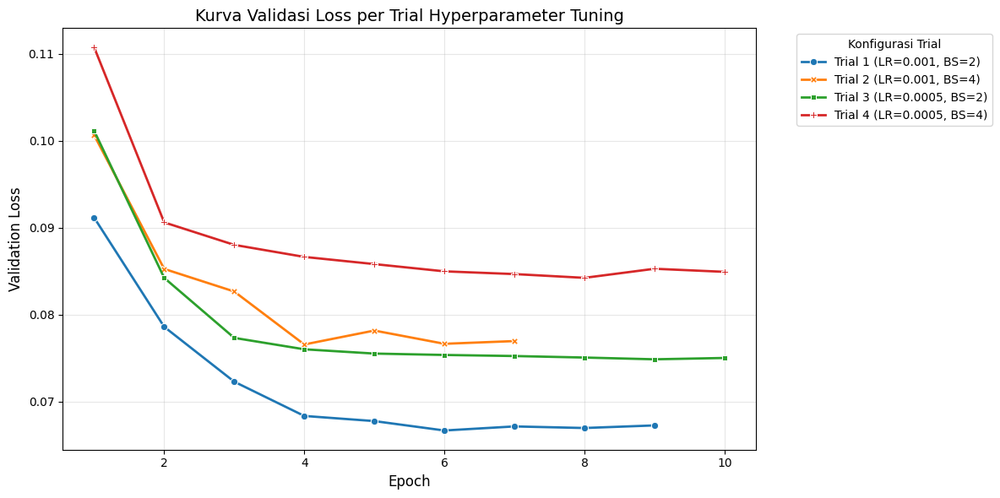

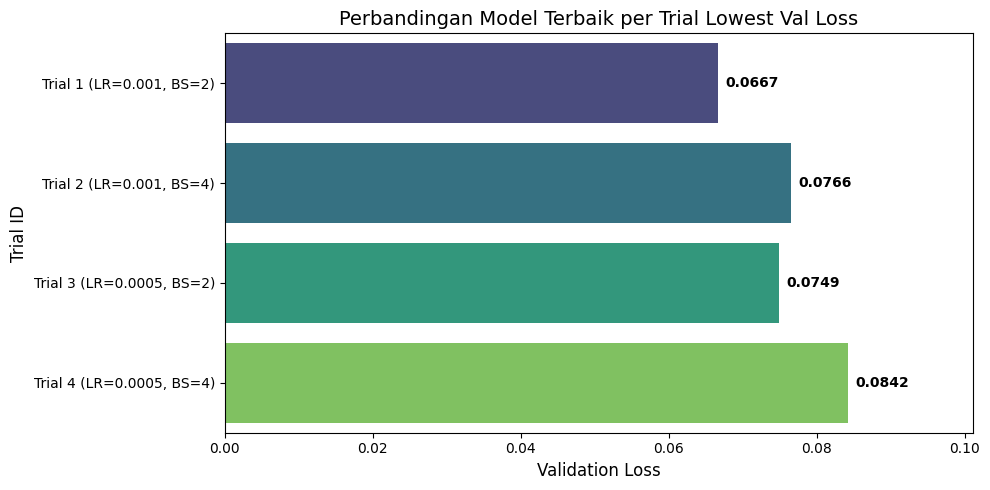

In [11]:
# PERSIAPAN DATA
# Membuat kolom label agar Legenda lebih jelas (Gabungan LR dan Batch Size)
results_df["Trial_Label"] = results_df.apply(
    lambda x: f"Trial {int(x['trial'])} (LR={x['lr']}, BS={int(x['batch_size'])})", axis=1
)

# VISUALISASI 1: LINE PLOT (EVOLUSI LOSS PER EPOCH) ---
# Ini menggantikan Bar Plot Anda agar tren penurunan loss terlihat jelas
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=results_df,
    x="epoch", 
    y="val_loss",
    hue="Trial_Label",  
    style="Trial_Label", 
    markers=True,
    dashes=False,
    linewidth=2
)

plt.title("Kurva Validasi Loss per Trial Hyperparameter Tuning", fontsize=14)
plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Validation Loss", fontsize=12)
plt.legend(title="Konfigurasi Trial", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# VISUALISASI 2: BAR PLOT (PERBANDINGAN HASIL TERBAIK)
# Ini versi perbaikan dari Bar Plot.
# Hanya mengambil nilai Loss TERENDAH dari setiap Trial untuk dibandingkan.

# Ambil loss minimum dari setiap trial
best_results = results_df.loc[results_df.groupby("trial")["val_loss"].idxmin()]

plt.figure(figsize=(10, 5))
barplot = sns.barplot(
    data=best_results,
    x="val_loss", 
    y="Trial_Label",
    hue="Trial_Label",
    palette="viridis",
    dodge=False
)

# Tambahkan angka loss di ujung bar
for i, v in enumerate(best_results["val_loss"]):
    plt.text(v + 0.001, i, f"{v:.4f}", color='black', va='center', fontweight='bold')

plt.title("Perbandingan Model Terbaik per Trial Lowest Val Loss", fontsize=14)
plt.xlabel("Validation Loss", fontsize=12)
plt.ylabel("Trial ID", fontsize=12)
plt.xlim(0, best_results["val_loss"].max() * 1.2) 
plt.legend([],[], frameon=False) 
plt.tight_layout()
plt.show()

Visualisasi Dari File CSV Hasil Tuning Trial

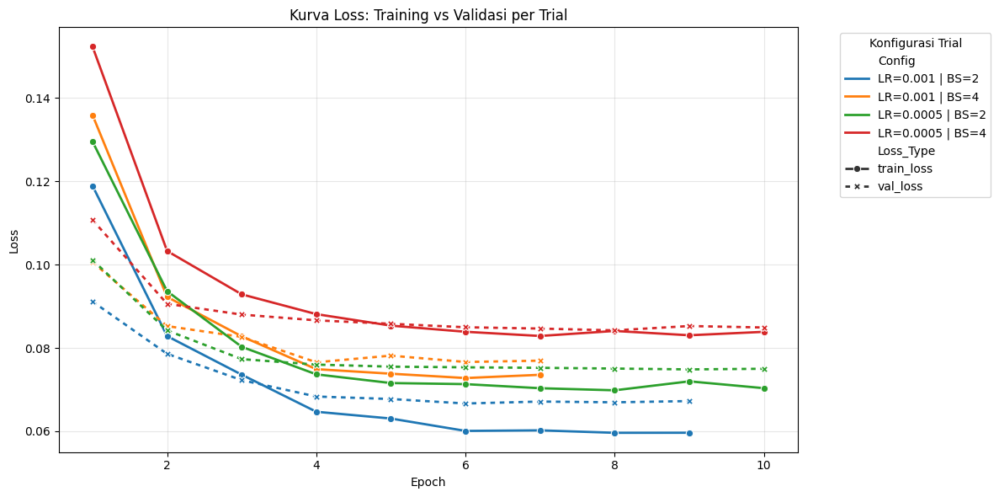

In [12]:
# Load Data
df = pd.read_csv("Result_Object_Detection/tuning_rcnn_trial.csv")

# PRE-PROCESSING (MELT DATA)
# Mengubah data agar kolom 'train_loss' dan 'val_loss' jadi satu kolom 'Loss_Value'
# Ini memudahkan Seaborn membedakan jenis garisnya.
df_melted = df.melt(
    id_vars=["epoch", "lr", "batch_size", "trial"], 
    value_vars=["train_loss", "val_loss"],
    var_name="Loss_Type", 
    value_name="Loss_Value"
)

# BUAT LABEL CONFIGURASI
# Menggabungkan LR dan Batch Size jadi satu label agar Legenda warna lebih jelas
df_melted["Config"] = df_melted.apply(
    lambda x: f"LR={x['lr']} | BS={int(x['batch_size'])}", axis=1
)

# 4. PLOTTING
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df_melted,
    x="epoch",
    y="Loss_Value",
    hue="Config",       # Warna berbeda untuk setiap Trial (Kombinasi LR & BS)
    style="Loss_Type",  # Bentuk Garis beda untuk Train vs Val
    markers=True,
    dashes={"train_loss": (1, 0), "val_loss": (2, 2)}, # (1,0)=Solid, (2,2)=Dashed
    linewidth=2
)

plt.title("Kurva Loss: Training vs Validasi per Trial")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True, alpha=0.3)

# Mengatur posisi legend agar tidak menutupi grafik
plt.legend(title="Konfigurasi Trial", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Memuat model terbaik dari: Result_Object_Detection\best_rcnn_trial.pth
Visualisasi Data Test:
Menampilkan 9 sampel acak dalam grid 3x3...


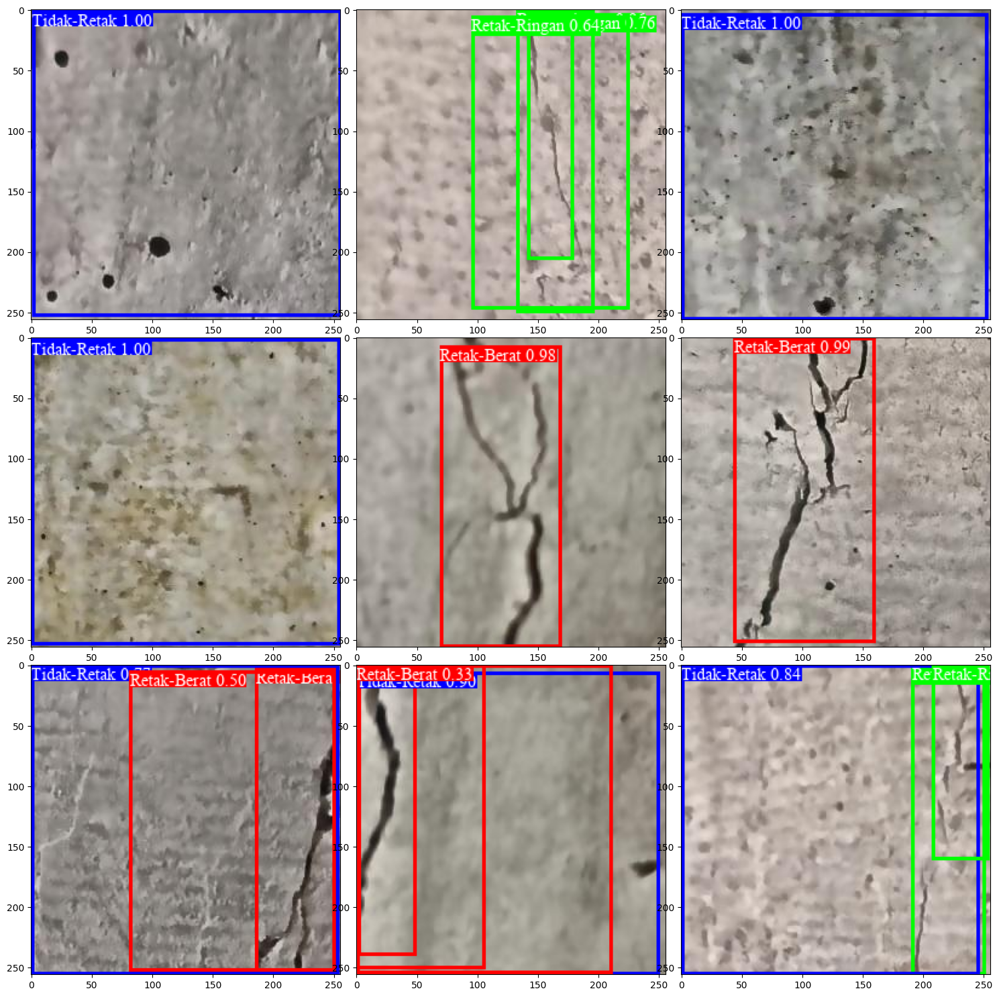

In [14]:
# Load Struktur Model
best_model = torchvision.models.detection.fasterrcnn_resnet50_fpn(weights=None)
in_features = best_model.roi_heads.box_predictor.cls_score.in_features
best_model.roi_heads.box_predictor = FastRCNNPredictor(in_features, NUM_CLASSES)

# Load Bobot (Perhatikan path folder 'checkpoints' jika file ada di sana)
# Cek path ini: kadang ada di folder 'checkpoints/', sesuaikan jika perlu.
ckpt_path = OUT_DIR / "Result_Object_Detection" / "best_rcnn_trial.pth" 
if not ckpt_path.exists():
    ckpt_path = OUT_DIR / "best_rcnn_trial.pth" 

if ckpt_path.exists():
    print(f"Memuat model terbaik dari: {ckpt_path}")
    best_model.load_state_dict(torch.load(ckpt_path, map_location=device))
    best_model.to(device)
    best_model.eval()
else:
    print(f"File checkpoint tidak ditemukan di {ckpt_path}!")

# Fungsi Visualisasi Grid
def show_inference_grid(model, dataset, rows=3, cols=3, conf_threshold=0.5):
    num_samples = rows * cols
    print(f"Menampilkan {num_samples} sampel acak dalam grid {rows}x{cols}...")
    
    # Ambil sampel acak
    indices = random.sample(range(len(dataset)), num_samples)
    
    # Buat Canvas Grid 
    fig, axes = plt.subplots(rows, cols, figsize=(15, 15))
    axes = axes.flatten() # Ratakan array axes agar mudah di-loop
    
    for i, idx in enumerate(indices):
        ax = axes[i]
        img, _ = dataset[idx] # img adalah Tensor
        
        # Prediksi
        with torch.no_grad():
            prediction = model([img.to(device)])[0]

        # Konversi ke PIL Image untuk digambar
        img_np = img.permute(1, 2, 0).cpu().numpy()
        img_pil = Image.fromarray((img_np * 255).astype(np.uint8))
        draw = ImageDraw.Draw(img_pil)

        # Ambil Data Prediksi
        boxes = prediction['boxes'].cpu().numpy()
        scores = prediction['scores'].cpu().numpy()
        labels = prediction['labels'].cpu().numpy()
        
        # Filter berdasarkan Threshold
        keep = scores >= conf_threshold
        
        # Gambar Kotak
        for box, score, label in zip(boxes[keep], scores[keep], labels[keep]):
            x1, y1, x2, y2 = box
            
            # Warna
            color_rgb = CLASS_COLORS.get(int(label), (255, 255, 255))
            
            # Draw Box
            draw.rectangle([x1, y1, x2, y2], outline=color_rgb, width=3)
            
            # Text Label & Background
            label_name = FINAL_ID_TO_NAME.get(int(label), str(label))
            text = f"{label_name} {score:.2f}"
            
            try:
                # Cara baru (Pillow 10+)
                bbox = draw.textbbox((x1, y1), text, font=font)
            except:
                # Cara lama (Fallback)
                w_text, h_text = draw.textsize(text, font=font)
                bbox = (x1, y1, x1 + w_text, y1 + h_text)
                
            draw.rectangle(bbox, fill=color_rgb)
            draw.text((x1, y1), text, font=font, fill=(255, 255, 255))

        # Tampilkan di Subplot
        ax.imshow(img_pil)
        ax.axis('on') 

    plt.tight_layout()
    plt.subplots_adjust(wspace=0.05, hspace=0.05)
    plt.show()

print("Visualisasi Data Test:")
show_inference_grid(best_model, test_ds, rows=3, cols=3, conf_threshold=0.3)

Training Ulang Model Terbaik

In [16]:
import time, json, torch, torchvision
from torch.utils.data import DataLoader

BEST_CFG = {
    "lr": 0.001,         # Ganti sesuai hasil tuning terbaik
    "batch_size": 4,     # Ganti sesuai hasil tuning terbaik (Saran: 2 atau 4)
    "epochs": 50,        # Batas maksimal epoch
    "wd": 0.0005,
    "patience": 5        # Stop jika tidak membaik selama 5 epoch
}

FINAL_EPOCHS = BEST_CFG["epochs"]
LOG_PATH = OUT_DIR / "train_log_final.json"
CHECKPOINT_DIR = OUT_DIR / "checkpoints"

print(f"Mulai Final Training dengan Config: {BEST_CFG}")

# PERSIAPAN DATALOADER (RE-INIT AGAR BATCH SIZE SESUAI)
train_loader = DataLoader(
    train_ds, 
    batch_size=BEST_CFG["batch_size"], 
    sampler=train_sampler, 
    collate_fn=collate_fn, 
    num_workers=0,
    pin_memory=True if torch.cuda.is_available() else False
)

valid_loader = DataLoader(
    valid_ds, 
    batch_size=BEST_CFG["batch_size"], 
    shuffle=False, 
    collate_fn=collate_fn, 
    num_workers=0
)

# INISIALISASI MODEL FINAL
model_final = torchvision.models.detection.fasterrcnn_resnet50_fpn(weights="DEFAULT")

# Ganti Head Predictor
in_features = model_final.roi_heads.box_predictor.cls_score.in_features
model_final.roi_heads.box_predictor = FastRCNNPredictor(in_features, NUM_CLASSES)

model_final = model_final.to(device)

# OPTIMIZER & SCHEDULER
params = [p for p in model_final.parameters() if p.requires_grad]
opt = torch.optim.SGD(
    params,
    lr=BEST_CFG["lr"],
    momentum=0.9,
    weight_decay=BEST_CFG["wd"]
)

# Scheduler: Turunkan LR jika loss validasi stagnan
sch = torch.optim.lr_scheduler.ReduceLROnPlateau(
    opt, mode="min", factor=0.5, patience=2
)

# LOOP TRAINING FINAL
train_losses, valid_losses, lrs = [], [], []
best_val_loss = float("inf")
no_improve = 0

print(f"\nTraining dimulai (Max {FINAL_EPOCHS} Epochs)")
start_time = time.time()

for ep in range(1, FINAL_EPOCHS+1):
    t0 = time.time()

    # Train & Validasi
    tl = train_one_epoch_amp(model_final, train_loader, opt, device, scaler)
    vl = eval_val_loss(model_final, valid_loader, device)

    # Step Scheduler
    sch.step(vl)
    lr_now = opt.param_groups[0]["lr"]

    # Logging
    train_losses.append(tl)
    valid_losses.append(vl)
    lrs.append(lr_now)

    elapsed = time.time() - t0
    print(f"[Epoch {ep}/{FINAL_EPOCHS}] "
          f"Train={tl:.4f} | Valid={vl:.4f} | "
          f"LR={lr_now:.6f} | Time={elapsed:.1f}s")

    # Simpan Model Terbaik
    if vl < best_val_loss:
        best_val_loss = vl
        no_improve = 0
        
        # Simpan state dict
        save_data = {
            "epoch": ep,
            "model_state": model_final.state_dict(),
            "optimizer_state": opt.state_dict(),
            "best_valid_loss": best_val_loss,
            "config": BEST_CFG,
            "class_names": FINAL_CLASS_NAMES
        }
        torch.save(save_data, OUT_DIR / "best_model_final_rcnn.pth")
        print(f"Model Terbaik Disimpan (Loss: {best_val_loss:.4f})")
    else:
        no_improve += 1
        print(f"Tidak ada perbaikan ({no_improve}/{BEST_CFG['patience']})")

    # Early Stopping
    if no_improve >= BEST_CFG["patience"]:
        print(f"\n[STOP] Early stopping terpicu pada epoch {ep}.")
        break

    # Checkpoint Berkala (Opsional: tiap 10 epoch)
    if ep % 10 == 0:
        torch.save(model_final.state_dict(), CHECKPOINT_DIR / f"checkpoint_ep{ep}.pth")

# SIMPAN LOG & PLOT HASIL
total_time = (time.time() - start_time) / 60
print(f"\nFinal Training Selesai dalam {total_time:.2f} menit.")

# Simpan Log JSON
with open(LOG_PATH, "w") as f:
    json.dump({
        "train_losses": train_losses,
        "valid_losses": valid_losses,
        "lrs": lrs,
        "best_valid_loss": best_val_loss
    }, f, indent=2)

Mulai Final Training dengan Config: {'lr': 0.001, 'batch_size': 4, 'epochs': 50, 'wd': 0.0005, 'patience': 5}

Training dimulai (Max 50 Epochs)


[Epoch 1/50] Train=0.1361 | Valid=0.1017 | LR=0.001000 | Time=3425.5s
Model Terbaik Disimpan (Loss: 0.1017)


[Epoch 2/50] Train=0.0937 | Valid=0.0940 | LR=0.001000 | Time=3398.7s
Model Terbaik Disimpan (Loss: 0.0940)


[Epoch 3/50] Train=0.0818 | Valid=0.0807 | LR=0.001000 | Time=3374.7s
Model Terbaik Disimpan (Loss: 0.0807)


[Epoch 4/50] Train=0.0760 | Valid=0.0779 | LR=0.001000 | Time=3340.5s
Model Terbaik Disimpan (Loss: 0.0779)


[Epoch 5/50] Train=0.0696 | Valid=0.0750 | LR=0.001000 | Time=3264.9s
Model Terbaik Disimpan (Loss: 0.0750)


... (11 outputs left out)

[Epoch 17/50] Train=0.0396 | Valid=0.0634 | LR=0.000500 | Time=3030.4s
Tidak ada perbaikan (2/5)


[Epoch 18/50] Train=0.0377 | Valid=0.0656 | LR=0.000250 | Time=3011.0s
Tidak ada perbaikan (3/5)


[Epoch 19/50] Train=0.0360 | Valid=0.0632 | LR=0.000250 | Time=2985.6s
Tidak ada perbaikan (4/5)


[Epoch 20/50] Train=0.0361 | Valid=0.0634 | LR=0.000250 | Time=3038.9s
Tidak ada perbaikan (5/5)

[STOP] Early stopping terpicu pada epoch 20.

Final Training Selesai dalam 1117.69 menit.


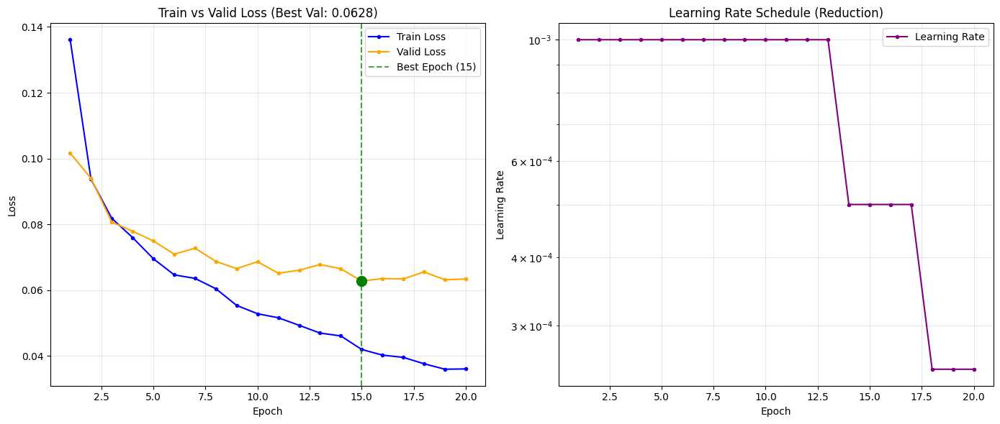

Grafik metrik tersimpan di: Result_Object_Detection\viz\final_training_metrics.png


In [18]:
actual_epochs = range(1, len(train_losses) + 1)

# Mencari lokasi epoch terbaik (Loss Validasi terendah)
best_val = min(valid_losses)
best_epoch_idx = valid_losses.index(best_val) + 1

#  PLOTTING
plt.figure(figsize=(14, 6))

# Subplot 1: Loss Curve
plt.subplot(1, 2, 1)
plt.plot(actual_epochs, train_losses, label="Train Loss", marker=".", color="blue")
plt.plot(actual_epochs, valid_losses, label="Valid Loss", marker=".", color="orange")

# Tandai Epoch Terbaik dengan Garis Vertikal
plt.axvline(x=best_epoch_idx, color='green', linestyle='--', alpha=0.7, label=f'Best Epoch ({best_epoch_idx})')
plt.scatter(best_epoch_idx, best_val, color='green', s=100, zorder=5) # Titik hijau tebal

plt.title(f"Train vs Valid Loss (Best Val: {best_val:.4f})")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

# Subplot 2: Learning Rate Schedule
plt.subplot(1, 2, 2)
plt.plot(actual_epochs, lrs, label="Learning Rate", color="purple", marker=".")

plt.title("Learning Rate Schedule (Reduction)")
plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.yscale("log") 
plt.legend()
plt.grid(True, alpha=0.3, which="both") # Grid halus untuk skala log

plt.tight_layout()

# Simpan Gambar
save_path = OUT_DIR / "viz" / "final_training_metrics.png"
save_path.parent.mkdir(parents=True, exist_ok=True) 

plt.savefig(save_path)
plt.show()

print(f"Grafik metrik tersimpan di: {save_path}")

Load Model Terbaik

In [19]:
def load_best_model(model_path, num_classes, device):
    # 1. Cek apakah file ada
    if not os.path.exists(model_path):
        raise FileNotFoundError(f"File model tidak ditemukan di: {model_path}")

    print(f"Loading model architecture...")
    
    # 2. Inisialisasi arsitektur model (Bobot kosong/random dulu)
    model = torchvision.models.detection.fasterrcnn_resnet50_fpn(
        weights=None, weights_backbone=None
    )
    
    # Sesuaikan Head Predictor dengan jumlah kelas kita
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)

    # 3. Load checkpoint
    print(f"Reading checkpoint from disk...")
    checkpoint = torch.load(model_path, map_location=device)

    # 4. Extract weights
    if isinstance(checkpoint, dict) and "model_state" in checkpoint:
        print("-> Detected metadata format (epoch, config, etc). Loading 'model_state'...")
        model.load_state_dict(checkpoint["model_state"])
        
        # Print Info Metadata jika ada
        ep = checkpoint.get('epoch', '?')
        loss = checkpoint.get('best_valid_loss', '?')
        print(f"-> Model Info: Epoch={ep}, Best Valid Loss={loss}")
        
    else:
        # Fallback: Jika file .pth hanya berisi state_dict langsung
        print("-> Detected raw state_dict format. Loading directly...")
        model.load_state_dict(checkpoint)

    # 5. Pindahkan ke device & set eval mode
    model = model.to(device)
    model.eval()
    
    print("Model loaded successfully and set to EVAL mode.")
    return model, checkpoint

path_to_model = OUT_DIR / "best_model_final_rcnn.pth"

try:
    loaded_model, checkpoint_info = load_best_model(path_to_model, NUM_CLASSES, device)
    
    # Cek config yang tersimpan (jika ada)
    if "config" in checkpoint_info:
        print("\nConfig saat training:", checkpoint_info["config"])
        
except Exception as e:
    print(f"\nTerjadi kesalahan saat memuat model: {e}")

Loading model architecture...
Reading checkpoint from disk...
-> Detected metadata format (epoch, config, etc). Loading 'model_state'...
-> Model Info: Epoch=15, Best Valid Loss=0.06278394946000643
Model loaded successfully and set to EVAL mode.

Config saat training: {'lr': 0.001, 'batch_size': 4, 'epochs': 50, 'wd': 0.0005, 'patience': 5}


Visualisasi Model Final

Memuat Model Final dari: Result_Object_Detection\best_model_final_rcnn.pth
Model Epoch 15 berhasil dimuat (Val Loss: 0.0628)

Menampilkan 9 prediksi pada Data Test (Threshold: 0.3)...


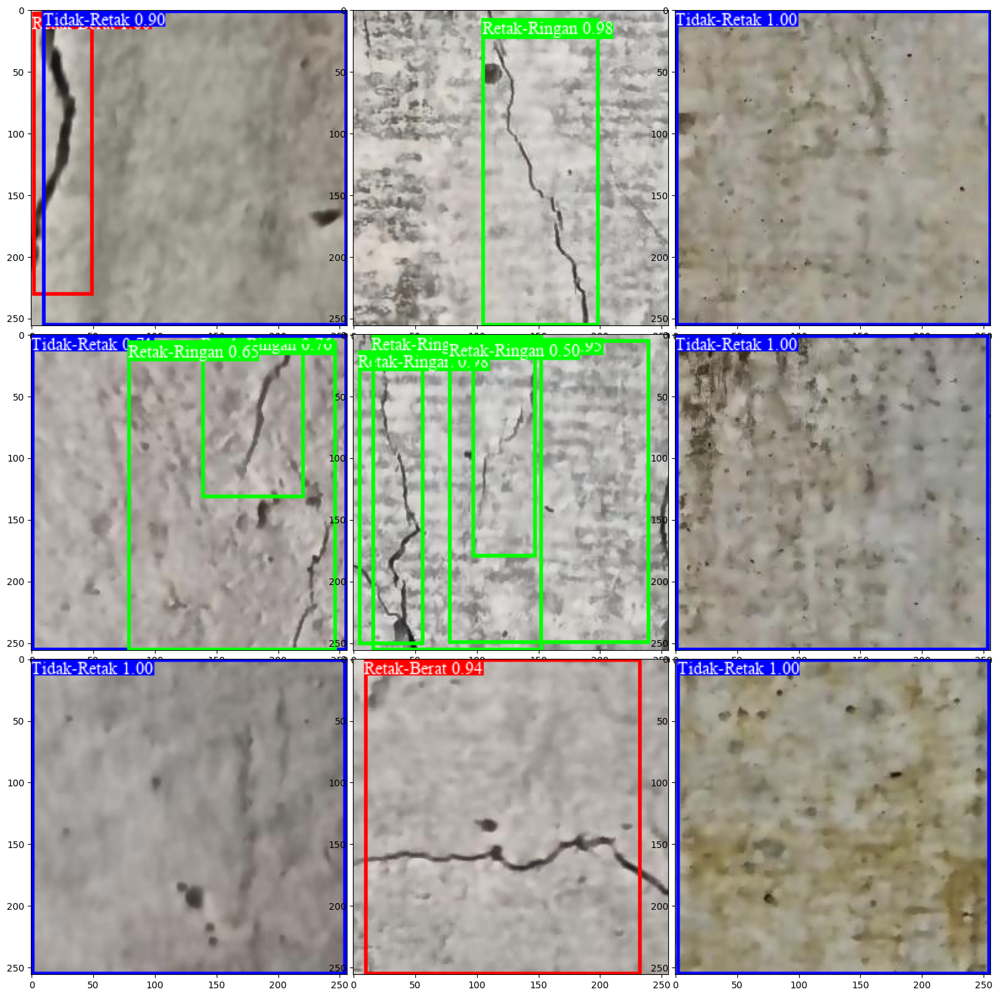

In [21]:
import random

# LOAD MODEL FINAL
ckpt_path = OUT_DIR / "best_model_final_rcnn.pth"

# Inisialisasi Struktur Model
best_model = torchvision.models.detection.fasterrcnn_resnet50_fpn(weights=None)
in_features = best_model.roi_heads.box_predictor.cls_score.in_features
best_model.roi_heads.box_predictor = FastRCNNPredictor(in_features, NUM_CLASSES)

# Load Bobot
if ckpt_path.exists():
    print(f"Memuat Model Final dari: {ckpt_path}")
    checkpoint = torch.load(ckpt_path, map_location=device)
    # Karena kita menyimpan dict lengkap
    best_model.load_state_dict(checkpoint['model_state'])
    best_model.to(device)
    best_model.eval()
    print(f"Model Epoch {checkpoint['epoch']} berhasil dimuat (Val Loss: {checkpoint['best_valid_loss']:.4f})")
else:
    print(f"File tidak ditemukan: {ckpt_path}")

# VISUALISASI
def show_inference_grid(model, dataset, rows=3, cols=3, conf_threshold=0.3):
    num_samples = rows * cols
    print(f"\nMenampilkan {num_samples} prediksi pada Data Test (Threshold: {conf_threshold})...")
    
    # Ambil sampel acak dari Test Set
    indices = random.sample(range(len(dataset)), num_samples)
    
    # Setup Canvas
    fig, axes = plt.subplots(rows, cols, figsize=(15, 15))
    axes = axes.flatten()
    
    for i, idx in enumerate(indices):
        ax = axes[i]
        img, _ = dataset[idx] # img is Tensor
        
        # Prediksi
        with torch.no_grad():
            prediction = model([img.to(device)])[0]

        # Convert ke Image PIL
        img_np = img.permute(1, 2, 0).cpu().numpy()
        img_pil = Image.fromarray((img_np * 255).astype(np.uint8))
        draw = ImageDraw.Draw(img_pil)

        # Ambil Data
        boxes = prediction['boxes'].cpu().numpy()
        scores = prediction['scores'].cpu().numpy()
        labels = prediction['labels'].cpu().numpy()
        
        # Filter Threshold
        keep = scores >= conf_threshold
        
        # Gambar Kotak
        for box, score, label in zip(boxes[keep], scores[keep], labels[keep]):
            x1, y1, x2, y2 = box
            
            # Warna Label
            color_rgb = CLASS_COLORS.get(int(label), (255, 255, 255))
            
            # Box
            draw.rectangle([x1, y1, x2, y2], outline=color_rgb, width=3)
            
            # Text Label
            label_name = FINAL_ID_TO_NAME.get(int(label), str(label))
            text = f"{label_name} {score:.2f}"
            
            # Text Background (Fallback support)
            try:
                bbox = draw.textbbox((x1, y1), text, font=font)
            except:
                w_text, h_text = draw.textsize(text, font=font)
                bbox = (x1, y1, x1 + w_text, y1 + h_text)
            
            draw.rectangle(bbox, fill=color_rgb)
            draw.text((x1, y1), text, font=font, fill=(255, 255, 255))

        # Tampilkan
        ax.imshow(img_pil)
        ax.axis('on') 
        
    plt.tight_layout()
    plt.subplots_adjust(wspace=0.02, hspace=0.02) 
    plt.show()

# EKSEKUSI
show_inference_grid(best_model, test_ds, rows=3, cols=3, conf_threshold=0.3)

Evaluasi mAP (mean Average Precision)

In [22]:
from pycocotools.cocoeval import COCOeval

@torch.no_grad()
def evaluate_map(model, loader, device, ann_file, save_json=True, out_name="predictions_test.json"):
    print(f"Memulai Evaluasi mAP pada: {ann_file}")
    
    model.eval()
    
    # 1. Load Ground Truth (GT) dari file JSON asli
    coco_gt = COCO(str(ann_file))
    
    results = []

    # 2. Loop Inference
    # Note: Loader kita hanya return images & targets (tidak ada paths)
    for images, targets in tqdm(loader, desc="Inference"):
        images = [img.to(device) for img in images]
        
        # Forward pass (mendapatkan prediksi)
        outputs = model(images)

        # 3. Format Output ke COCO Result
        for target, output in zip(targets, outputs):
            image_id = target["image_id"].item() # Ambil ID gambar
            
            # Pindahkan ke CPU numpy
            boxes = output["boxes"].cpu().numpy()
            scores = output["scores"].cpu().numpy()
            labels = output["labels"].cpu().numpy()

            for box, score, label in zip(boxes, scores, labels):
                # Convert XYXY (PyTorch) -> XYWH (COCO)
                x1, y1, x2, y2 = box
                w, h = x2 - x1, y2 - y1
                
                results.append({
                    "image_id": int(image_id),
                    "category_id": int(label),
                    "bbox": [float(x1), float(y1), float(w), float(h)],
                    "score": float(score)
                })

    # 4. Handling jika tidak ada deteksi sama sekali
    if len(results) == 0:
        print("Peringatan: Model tidak mendeteksi objek apapun pada dataset ini.")
        return None, {}

    # 5. Simpan Hasil Prediksi ke JSON (Opsional tapi berguna untuk debug)
    if save_json:
        pred_path = OUT_DIR / out_name
        with open(pred_path, "w") as f:
            json.dump(results, f)
        print(f"Prediksi disimpan di: {pred_path}")

    # 6. Jalankan COCO Eval
    print("Menghitung statistik mAP")
    coco_dt = coco_gt.loadRes(results) # Load Detections
    
    coco_eval = COCOeval(coco_gt, coco_dt, iouType="bbox")
    coco_eval.evaluate()
    coco_eval.accumulate()
    coco_eval.summarize()

    # 7. Ambil Statistik
    stats = {
        "mAP (AP @ IoU=0.50:0.95)": coco_eval.stats[0],
        "mAP50 (AP @ IoU=0.50)": coco_eval.stats[1],
        "mAP75 (AP @ IoU=0.75)": coco_eval.stats[2],
        "AP_Small": coco_eval.stats[3],
        "AP_Medium": coco_eval.stats[4],
        "AP_Large": coco_eval.stats[5],
    }
    
    return coco_eval, stats

# Pastikan 'best_model' sudah di-load (dari langkah sebelumnya)
print("\nHASIL EVALUASI mAP DATA TEST")
eval_results, map_stats = evaluate_map(
    best_model, 
    test_loader, 
    device, 
    ANNOT_FILES['test'], 
    out_name="test_predictions_rcnn.json"
)

print("\nRingkasan Metrik:")
for k, v in map_stats.items():
    print(f"{k}: {v:.4f}")


HASIL EVALUASI mAP DATA TEST
Memulai Evaluasi mAP pada: Tanggul\eksperimen\dataset\augmentasi_bbox\test\test_annotations.coco.json
loading annotations into memory...
Done (t=0.03s)
creating index...
index created!


Inference: 100%|███████████████████████████████████████████████████████████████████████| 23/23 [00:29<00:00,  1.28s/it]


Prediksi disimpan di: Result_Object_Detection\test_predictions_rcnn.json
Menghitung statistik mAP
Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.11s).
Accumulating evaluation results...
DONE (t=0.06s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.617
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.822
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.623
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = -1.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.335
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.649
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.658
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.747
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=

Visualisasi Hasil Evaluasi

C:\Users\Pongo\AppData\Local\Temp\ipykernel_11872\2415926373.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=df_eval, x="Metric", y="Score", palette="viridis")


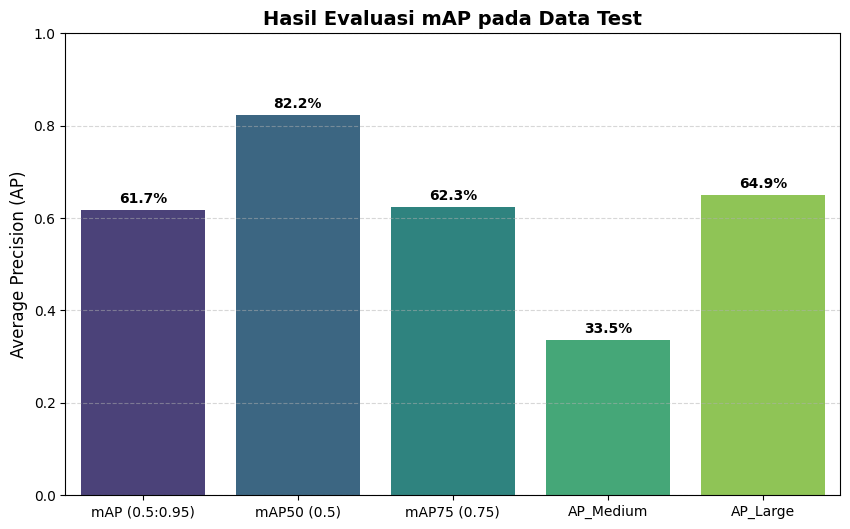

Grafik mAP tersimpan di: Result_Object_Detection\viz\map_evaluation_chart.png


In [23]:
eval_data = {
    "Metric": ["mAP (0.5:0.95)", "mAP50 (0.5)", "mAP75 (0.75)", "AP_Medium", "AP_Large"],
    "Score": [0.6171, 0.8223, 0.6234, 0.3349, 0.6488]
}

df_eval = pd.DataFrame(eval_data)

plt.figure(figsize=(10, 6))
ax = sns.barplot(data=df_eval, x="Metric", y="Score", palette="viridis")

# Menambahkan angka di atas batang
for i, v in enumerate(df_eval["Score"]):
    ax.text(i, v + 0.01, f"{v:.1%}", ha='center', va='bottom', fontweight='bold')

plt.ylim(0, 1.0) # Skala 0 sampai 100%
plt.title("Hasil Evaluasi mAP pada Data Test", fontsize=14, fontweight='bold')
plt.ylabel("Average Precision (AP)", fontsize=12)
plt.xlabel("")
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Simpan
save_path = OUT_DIR / "viz" / "map_evaluation_chart.png"
save_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(save_path, dpi=300)
plt.show()

print(f"Grafik mAP tersimpan di: {save_path}")

Visualisasi Hasil Evaluasi

Visualisasi tersimpan di: Result_Object_Detection\viz\final_map_ar_chart.png


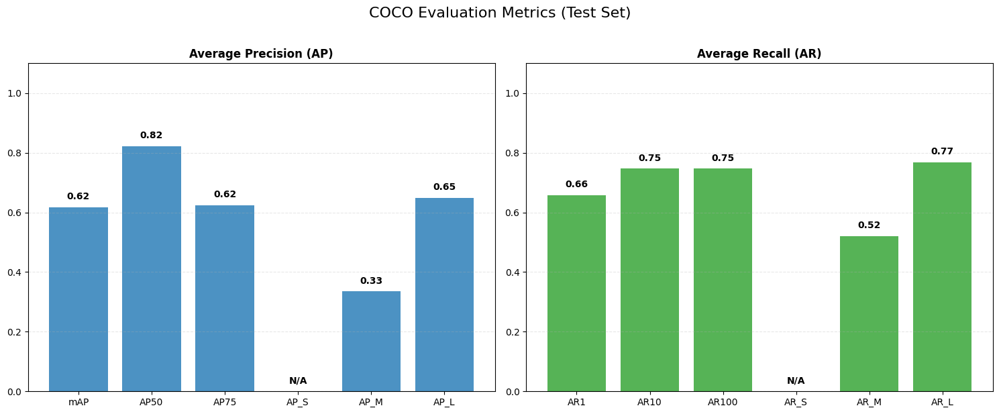

In [24]:
def plot_map_results(coco_eval_obj, out_path=None):
    """
    Visualisasi lengkap AP dan AR dari objek COCOeval
    """
    # Ambil 12 statistik standar dari COCO
    # Format: [AP, AP50, AP75, AP_S, AP_M, AP_L, AR1, AR10, AR100, AR_S, AR_M, AR_L]
    stats = coco_eval_obj.stats
    
    # Ganti nilai -1 (tidak ada data) menjadi 0 untuk plotting, tapi simpan info aslinya
    plot_vals = [max(0, x) for x in stats]
    
    # 1. Definisi Label
    ap_labels = ["mAP", "AP50", "AP75", "AP_S", "AP_M", "AP_L"]
    ap_vals   = plot_vals[:6]
    
    ar_labels = ["AR1", "AR10", "AR100", "AR_S", "AR_M", "AR_L"]
    ar_vals   = plot_vals[6:]

    # 2. Setup Canvas
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    
    # PLOT 1: Average Precision (AP)
    bars_ap = axes[0].bar(ap_labels, ap_vals, color="#1f77b4", alpha=0.8)
    axes[0].set_title("Average Precision (AP)", fontsize=12, fontweight='bold')
    axes[0].set_ylim(0, 1.1)
    axes[0].grid(axis="y", linestyle='--', alpha=0.3)
    
    # Label Text AP
    for i, (bar, val) in enumerate(zip(bars_ap, ap_vals)):
        height = bar.get_height()
        # Cek jika nilai asli -1 (artinya tidak ada data)
        text_label = "N/A" if stats[i] == -1 else f"{val:.2f}"
        axes[0].text(bar.get_x() + bar.get_width()/2, height + 0.02, text_label, 
                     ha="center", va="bottom", fontsize=10, fontweight='bold')

    # PLOT 2: Average Recall (AR)
    bars_ar = axes[1].bar(ar_labels, ar_vals, color="#2ca02c", alpha=0.8)
    axes[1].set_title("Average Recall (AR)", fontsize=12, fontweight='bold')
    axes[1].set_ylim(0, 1.1)
    axes[1].grid(axis="y", linestyle='--', alpha=0.3)
    
    # Label Text AR
    for i, (bar, val) in enumerate(zip(bars_ar, ar_vals)):
        height = bar.get_height()
        # Offset index +6 karena AR ada di paruh kedua list stats
        text_label = "N/A" if stats[i+6] == -1 else f"{val:.2f}"
        axes[1].text(bar.get_x() + bar.get_width()/2, height + 0.02, text_label, 
                     ha="center", va="bottom", fontsize=10, fontweight='bold')

    # 3. Finalisasi
    plt.suptitle("COCO Evaluation Metrics (Test Set)", fontsize=16, y=1.02)
    plt.tight_layout()
    
    if out_path:
        plt.savefig(out_path, dpi=300, bbox_inches='tight')
        print(f"Visualisasi tersimpan di: {out_path}")
        
    plt.show()

# 'eval_results' adalah objek coco_eval yang dikembalikan fungsi evaluate_map
save_file = OUT_DIR / "viz" / "final_map_ar_chart.png"
plot_map_results(eval_results, out_path=save_file)

Visualisasi Kurva Training Final Loss & Learning Rate

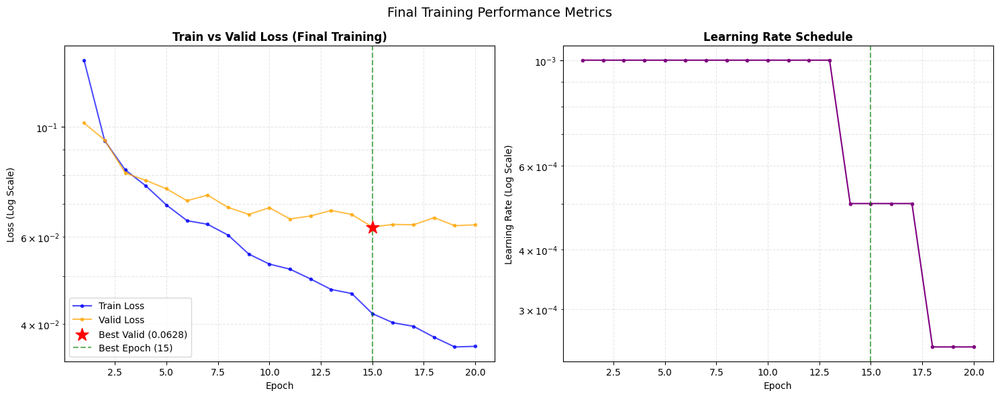

Grafik visualisasi tersimpan di: Result_Object_Detection\viz\final_training_curves_rcnn.png


In [26]:
# epochs dinamis berdasarkan panjang data loss
epochs = range(1, len(train_losses) + 1)

# Setup Canvas
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# SUBPLOT 1: TRAIN VS VALID LOSS ---
# Plot Garis
axes[0].plot(epochs, train_losses, label="Train Loss", linestyle="-", marker=".", color="blue", alpha=0.7)
axes[0].plot(epochs, valid_losses, label="Valid Loss", linestyle="-", marker=".", color="orange", alpha=0.7)

# Cari & Tandai Best Model
best_idx = np.argmin(valid_losses) + 1
best_val = min(valid_losses)

# Titik Merah Besar (Bintang)
axes[0].scatter(best_idx, best_val, color="red", marker="*", s=200, zorder=5, 
                label=f"Best Valid ({best_val:.4f})")

# Garis Vertikal Penanda Epoch Terbaik
axes[0].axvline(x=best_idx, color="green", linestyle="--", alpha=0.6, label=f"Best Epoch ({best_idx})")

# Dekorasi
axes[0].set_title("Train vs Valid Loss (Final Training)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss (Log Scale)")
axes[0].set_yscale("log") # Log scale agar selisih kecil terlihat
axes[0].grid(True, which="both", linestyle="--", alpha=0.3)
axes[0].legend()

# SUBPLOT 2: LEARNING RATE SCHEDULE 
axes[1].plot(epochs, lrs, marker=".", color="purple", linestyle="-")

# Garis Vertikal (agar sinkron dengan grafik kiri)
axes[1].axvline(x=best_idx, color="green", linestyle="--", alpha=0.6, label=f"Best Epoch ({best_idx})")

# Dekorasi
axes[1].set_title("Learning Rate Schedule", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Learning Rate (Log Scale)")
axes[1].set_yscale("log") # LR lebih informatif dengan Log Scale
axes[1].grid(True, which="both", linestyle="--", alpha=0.3)

# FINALISASI
plt.suptitle("Final Training Performance Metrics", fontsize=14, y=0.98)
plt.tight_layout()

# Simpan
save_path = OUT_DIR / "viz" / "final_training_curves_rcnn.png"
save_path.parent.mkdir(parents=True, exist_ok=True) 

plt.savefig(save_path, dpi=300)
plt.show()

print(f"Grafik visualisasi tersimpan di: {save_path}")

Membuat all_y_true dan all_y_pred

In [31]:
import torchvision.ops as ops

ID_TIDAK_RETAK = FINAL_NAME_TO_ID.get("Tidak-Retak", 3)

all_y_true = []
all_y_pred = []

# Konfigurasi Threshold
IOU_THRESHOLD = 0.5   # Standar COCO (Overlap minimal 50%)
CONF_THRESHOLD = 0.3  # Hanya ambil prediksi dengan confidence > 30%

model_final.eval()
print("Menghitung Confusion Matrix dengan IoU Matching")

with torch.no_grad():
    for images, targets in tqdm(test_loader, desc="Matching Boxes"):
        images = [img.to(device) for img in images]
        outputs = model_final(images)

        for tgt, out in zip(targets, outputs):
            # 1. Ambil Data Ground Truth
            gt_boxes = tgt["boxes"].to(device)
            gt_labels = tgt["labels"].to(device)

            # 2. Ambil Data Prediksi & Filter Score
            pred_boxes = out["boxes"].to(device)
            pred_scores = out["scores"].to(device)
            pred_labels = out["labels"].to(device)

            # Filter: Buang prediksi yang confidence-nya rendah
            keep_idxs = pred_scores > CONF_THRESHOLD
            pred_boxes = pred_boxes[keep_idxs]
            pred_labels = pred_labels[keep_idxs]

            # 3. Kasus A: Jika Gambar Kosong (Tidak ada GT)
            if len(gt_boxes) == 0:
                # Jika ada prediksi padahal GT kosong -> False Positive
                # Kita bisa skip atau catat sebagai background, tapi untuk CM biasanya fokus ke objek
                continue

            # 4. Kasus B: Jika Model Tidak Memprediksi Apapun
            if len(pred_boxes) == 0:
                # Semua GT dianggap tidak terdeteksi (Missed / False Negative)
                for label in gt_labels:
                    all_y_true.append(int(label.item()))
                    all_y_pred.append(ID_TIDAK_RETAK) # Anggap terprediksi sebagai "Tidak-Retak"
                continue

            # 5. LOGIKA UTAMA: MATCHING DENGAN IOU ---
            # Hitung IoU antara SEMUA GT vs SEMUA Prediksi di gambar ini
            # Output shape: [N_gt, M_pred]
            iou_matrix = ops.box_iou(gt_boxes, pred_boxes)

            # Loop setiap Ground Truth untuk mencari pasangannya
            for i in range(len(gt_labels)):
                gt_label = int(gt_labels[i].item())
                
                # Cari prediksi dengan IoU terbesar untuk GT ke-i ini
                max_iou, max_idx = iou_matrix[i].max(dim=0)
                
                if max_iou > IOU_THRESHOLD:
                    # KETEMU: Ada kotak prediksi yang overlap cukup besar
                    matched_pred_label = int(pred_labels[max_idx].item())
                    all_y_true.append(gt_label)
                    all_y_pred.append(matched_pred_label)
                else:
                    # TIDAK KETEMU: Overlap terlalu kecil atau meleset
                    # Ini dihitung sebagai Missed Detection (Model gagal lihat retak)
                    all_y_true.append(gt_label)
                    all_y_pred.append(ID_TIDAK_RETAK)

print(f"Selesai. Total sampel untuk Confusion Matrix: {len(all_y_true)}")

Menghitung Confusion Matrix dengan IoU Matching


Matching Boxes: 100%|██████████████████████████████████████████████████████████████████| 23/23 [00:53<00:00,  2.31s/it]

Selesai. Total sampel untuk Confusion Matrix: 90


Classification Report & Confusion Matrix

METRIK EVALUASI LEVEL KELAS (SKLEARN)
Precision (Macro Avg)  : 0.9090
Recall (Macro Avg)     : 0.9028
F1-Score (Macro Avg)   : 0.8999

Classification Report Per Kelas
              precision    recall  f1-score   support

 Retak-Berat       0.97      0.88      0.92        32
Retak-Ringan       0.96      0.83      0.89        30
 Tidak-Retak       0.80      1.00      0.89        28

    accuracy                           0.90        90
   macro avg       0.91      0.90      0.90        90
weighted avg       0.91      0.90      0.90        90


Visualisasi Confusion Matrix


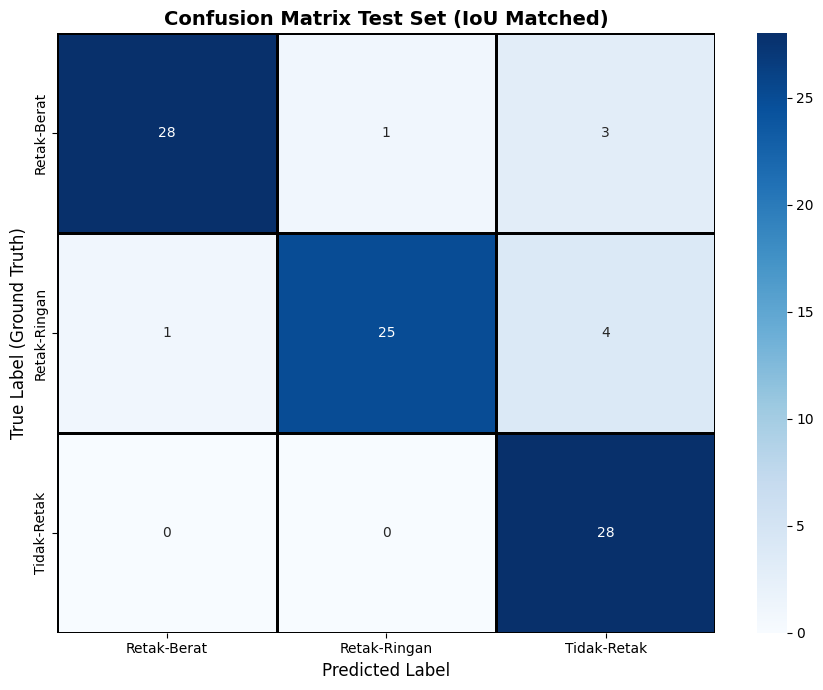

Confusion Matrix visualisasi tersimpan di: Result_Object_Detection\viz\confusion_matrix_rcnn.png


In [32]:
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report, confusion_matrix

# 1. SETUP LABEL
# Pastikan urutan label sesuai dengan konfigurasi awal
# FINAL_CLASS_NAMES = ["Retak-Berat", "Retak-Ringan", "Tidak-Retak"]
# Ambil ID yang sesuai: [1, 2, 3]
target_ids = [FINAL_NAME_TO_ID[name] for name in FINAL_CLASS_NAMES]

print("METRIK EVALUASI LEVEL KELAS (SKLEARN)")

# 2. HITUNG MACRO AVERAGE
precision = precision_score(all_y_true, all_y_pred, labels=target_ids, average='macro', zero_division=0)
recall    = recall_score(all_y_true, all_y_pred, labels=target_ids, average='macro', zero_division=0)
f1        = f1_score(all_y_true, all_y_pred, labels=target_ids, average='macro', zero_division=0)

print(f"Precision (Macro Avg)  : {precision:.4f}")
print(f"Recall (Macro Avg)     : {recall:.4f}")
print(f"F1-Score (Macro Avg)   : {f1:.4f}")

# 3. CLASSIFICATION REPORT
print("\nClassification Report Per Kelas")
print(classification_report(
    all_y_true, 
    all_y_pred, 
    labels=target_ids,        # [1, 2, 3]
    target_names=FINAL_CLASS_NAMES, # Label Text
    zero_division=0
))

# 4. CONFUSION MATRIX
print("\nVisualisasi Confusion Matrix")
cm = confusion_matrix(all_y_true, all_y_pred, labels=target_ids)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', linewidths=1, linecolor='black',
            xticklabels=FINAL_CLASS_NAMES, 
            yticklabels=FINAL_CLASS_NAMES)

plt.title('Confusion Matrix Test Set (IoU Matched)', fontsize=14, fontweight='bold')
plt.ylabel('True Label (Ground Truth)', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.tight_layout()

# Simpan ke folder viz
save_path = OUT_DIR / "viz" / "confusion_matrix_rcnn.png"
save_path.parent.mkdir(parents=True, exist_ok=True)

plt.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()

print(f"Confusion Matrix visualisasi tersimpan di: {save_path}")

Visualisasi Hasil Prediksi

In [33]:
from torchvision.transforms import functional as F

# 1. SETUP OUTPUT DIR
OUTPUT_VIS_DIR = OUT_DIR / "hasil_prediksi_rcnn"
OUTPUT_VIS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Hasil visualisasi akan disimpan di: {OUTPUT_VIS_DIR}")

# 2. CONFIG FONT
try:
    font = ImageFont.truetype("arial.ttf", 14)
except IOError:
    font = ImageFont.load_default()

# 3. EKSEKUSI VISUALISASI
try:
    # Cek ketersediaan variabel
    if 'model_final' not in locals():
        raise NameError("model_final belum dimuat. Pastikan Anda sudah load model terbaik.")
    if 'test_loader' not in locals():
        raise NameError("test_loader tidak ditemukan.")

    model_final.eval()
    total_saved = 0
    CONF_THRESHOLD = 0.5 # Hanya simpan prediksi dengan confidence > 50%

    print("Memproses visualisasi seluruh Test Set")
    
    # Gunakan no_grad agar hemat memori
    with torch.no_grad():
        # Loop batch
        for images, targets in tqdm(test_loader, desc="Saving Predictions"):
            # Pindahkan image ke device untuk prediksi
            images_gpu = [img.to(device) for img in images]
            outputs = model_final(images_gpu)

            # Loop per gambar dalam batch
            for i, (img_tensor, output) in enumerate(zip(images, outputs)):
                
                # A. Dapatkan Nama File Asli dari Target
                # Kita ambil ID gambar dari target, lalu cari di metadata dataset
                img_id = targets[i]["image_id"].item()
                img_info = test_ds.coco.loadImgs(img_id)[0]
                file_name_ori = img_info["file_name"]

                # B. Konversi Tensor ke PIL Image
                # Denormalize tidak perlu karena FasterRCNN inputnya 0-1
                img_pil = F.to_pil_image(img_tensor.cpu())
                draw = ImageDraw.Draw(img_pil)

                # C. Ambil Data Prediksi
                boxes = output["boxes"].cpu()
                scores = output["scores"].cpu()
                labels = output["labels"].cpu()

                # Filter Threshold
                keep = scores >= CONF_THRESHOLD
                boxes = boxes[keep]
                scores = scores[keep]
                labels = labels[keep]

                # D. Gambar Kotak & Label
                for box, label, score in zip(boxes, labels, scores):
                    x1, y1, x2, y2 = box.tolist()
                    cat_id = int(label.item())
                    
                    # Ambil Warna & Nama dari Config Global
                    # Default putih jika ID tidak dikenal
                    color = CLASS_COLORS.get(cat_id, (255, 255, 255)) 
                    class_name = FINAL_ID_TO_NAME.get(cat_id, str(cat_id))
                    
                    text_label = f"{class_name} {score:.2f}"

                    # Gambar Box
                    draw.rectangle([x1, y1, x2, y2], outline=color, width=3)

                    # Gambar Background Teks
                    try:
                        bbox = draw.textbbox((x1, y1), text_label, font=font)
                    except AttributeError:
                        w_text, h_text = draw.textsize(text_label, font=font)
                        bbox = (x1, y1, x1 + w_text, y1 + h_text)
                    
                    draw.rectangle(bbox, fill=color)
                    draw.text((x1, y1), text_label, fill="white", font=font)

                # E. Simpan Gambar
                # Tambahkan prefix 'pred_'
                save_name = f"pred_{os.path.basename(file_name_ori)}"
                save_full_path = OUTPUT_VIS_DIR / save_name
                
                img_pil.save(save_full_path)
                total_saved += 1

    print(f"\nSUKSES: {total_saved} gambar hasil prediksi disimpan di '{OUTPUT_VIS_DIR}'")

except NameError as e:
    print(f"\nERROR: {e}")
except Exception as e:
    print(f"\nERROR saat visualisasi: {e}")

Hasil visualisasi akan disimpan di: Result_Object_Detection\hasil_prediksi_rcnn
Memproses visualisasi seluruh Test Set


Saving Predictions: 100%|██████████████████████████████████████████████████████████████| 23/23 [00:53<00:00,  2.32s/it]


SUKSES: 90 gambar hasil prediksi disimpan di 'Result_Object_Detection\hasil_prediksi_rcnn'


Visualisasi Sampel Prediksi

Menampilkan 9 sampel prediksi3x3


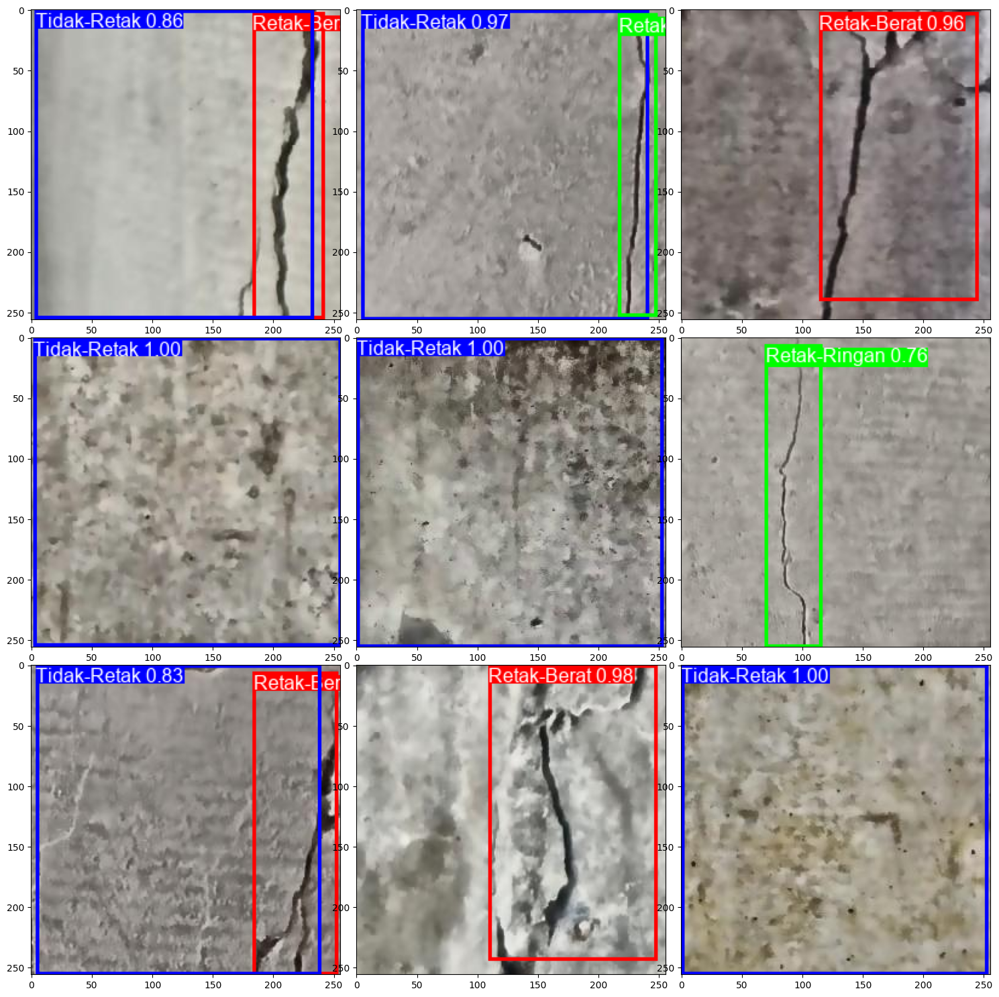

Gambar Grid tersimpan di: Result_Object_Detection\viz\result_predictions_rcnn.png


In [34]:
from PIL import ImageDraw, ImageFont

NUM_SAMPLES = 9  # Total gambar 
ROWS = 3         # Jumlah baris
COLS = 3         # Jumlah kolom 

try:
    # 1. Cek Ketersediaan Variabel
    if 'model_final' not in locals():
        raise NameError("model_final belum dimuat")
    if 'test_ds' not in locals():
        raise NameError("test_ds (dataset) tidak ditemukan")

    # 2. Ambil Sampel Acak dari Dataset Test
    indices = random.sample(range(len(test_ds)), NUM_SAMPLES)
    
    print(f"Menampilkan {NUM_SAMPLES} sampel prediksi{ROWS}x{COLS}")

    # 3. Setup Canvas
    # figsize=(15, 15) membuat gambar besar dan kotak
    fig, axes = plt.subplots(ROWS, COLS, figsize=(15, 15))
    axes = axes.flatten() # Ratakan array axes agar mudah di-loop (0 sampai 8)

    # 4. Setup Font
    try:
        font = ImageFont.truetype("arial.ttf", 16)
    except IOError:
        font = ImageFont.load_default()

    # 5. Loop untuk setiap slot grid
    model_final.eval()
    
    for i, idx in enumerate(indices):
        ax = axes[i]
        
        # Load Data
        img_tensor, target = test_ds[idx]
        
        # Prediksi
        with torch.no_grad():
            output = model_final([img_tensor.to(device)])[0]

        # Convert ke PIL untuk Menggambar
        img_pil = F.to_pil_image(img_tensor.cpu())
        draw = ImageDraw.Draw(img_pil)

        # Ambil Data Prediksi
        pred_boxes = output["boxes"].cpu()
        pred_labels = output["labels"].cpu()
        pred_scores = output["scores"].cpu()

        # Filter Threshold
        keep = pred_scores >= 0.5
        
        for box, label, score in zip(pred_boxes[keep], pred_labels[keep], pred_scores[keep]):
            x1, y1, x2, y2 = box.tolist()
            cat_id = int(label.item())
            
            # Ambil Warna & Nama 
            color = CLASS_COLORS.get(cat_id, (255, 0, 0)) 
            name = FINAL_ID_TO_NAME.get(cat_id, str(cat_id))
            text = f"{name} {score:.2f}"
            
            # Gambar Kotak
            draw.rectangle([x1, y1, x2, y2], outline=color, width=3)
            
            # Gambar Latar Teks
            bbox = draw.textbbox((x1, y1), text, font=font)
            draw.rectangle(bbox, fill=color)
            draw.text((x1, y1), text, fill="white", font=font)

        # Tampilkan di Subplot
        ax.imshow(img_pil)
        # ax.set_title(f"ID: {idx}", fontsize=10) # Opsional: tampilkan ID
        ax.axis("on") # Hilangkan sumbu X/Y agar tampilan bersih

    # 6. Rapikan Layout
    plt.tight_layout()
    plt.subplots_adjust(wspace=0.05, hspace=0.05)
    
    # Simpan Hasil
    save_path = OUT_DIR / "viz" / "result_predictions_rcnn.png"
    save_path.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(save_path, dpi=150)
    
    plt.show()
    print(f"Gambar Grid tersimpan di: {save_path}")

except NameError as e:
    print(f"\nFATAL ERROR: {e}")
except Exception as e:
    print(f"Terjadi error saat visualisasi: {e}")

Model Inference

In [45]:
# 1. KONFIGURASI PATH & DEVICE
OUT_DIR = Path("Result_Object_Detection")
MODEL_FILE = OUT_DIR / "best_model_final_rcnn.pth"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. DEFINISI KELAS
# Sesuai dataset crack detection
CLASS_NAMES = ["Retak-Berat", "Retak-Ringan", "Tidak-Retak"]
NUM_CLASSES = len(CLASS_NAMES) + 1  # +1 untuk background (ID 0)

# 3. MUAT MODEL TERLATIH
print(f"Sedang memuat model dari: {MODEL_FILE}")

try:
    # A. Inisialisasi Arsitektur Base Faster R-CNN
    model = torchvision.models.detection.fasterrcnn_resnet50_fpn(weights=None, weights_backbone=None)
    
    # B. Sesuaikan Head Predictor
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, NUM_CLASSES)

    # C. Load Checkpoint dari Disk
    if MODEL_FILE.exists():
        checkpoint = torch.load(MODEL_FILE, map_location=DEVICE)
        
        # Handling format penyimpanan (Dictionary vs State Dict)
        if isinstance(checkpoint, dict) and "model_state" in checkpoint:
            # Jika format dictionary lengkap (Epoch, Config, Model State)
            model.load_state_dict(checkpoint["model_state"])
            ep_info = checkpoint.get('epoch', 'N/A')
            loss_info = checkpoint.get('best_valid_loss', 'N/A')
            print(f"Berhasil memuat CHECKPOINT LENGKAP.")
            print(f"   - Epoch Terbaik  : {ep_info}")
            print(f"   - Valid Loss     : {loss_info}")
        else:
            # Jika format raw state_dict
            model.load_state_dict(checkpoint)
            print("Berhasil memuat RAW STATE DICT.")

        # D. Pindahkan ke Device & Set Eval
        model = model.to(DEVICE)
        model.eval() # SANGAT PENTING: Mematikan Dropout & Batch Norm update
        
    else:
        raise FileNotFoundError(f"File tidak ditemukan di path: {MODEL_FILE}")

except FileNotFoundError as e:
    print(f"\nGAGAL: {e}")
    model = None
except Exception as e:
    print(f"\nERROR UTAMA: {e}")
    model = None

# 4. VERIFIKASI KONFIGURASI
if model is not None:
    print("\nVerifikasi Konfigurasi Inferensi")
    print(f"Device           : {DEVICE}")
    print(f"Jumlah Kelas     : {NUM_CLASSES}")
    print(f"Label Kelas      : {CLASS_NAMES}")
    
    if len(CLASS_NAMES) != (NUM_CLASSES - 1):
        print("PERINGATAN: Jumlah nama kelas tidak sinkron dengan NUM_CLASSES!")
    else:
        print("Konfigurasi Kelas Sesuai.")
        
    print("\nModel SIAP digunakan untuk deteksi.")

Sedang memuat model dari: Result_Object_Detection\best_model_final_rcnn.pth
Berhasil memuat CHECKPOINT LENGKAP.
   - Epoch Terbaik  : 15
   - Valid Loss     : 0.06278394946000643

Verifikasi Konfigurasi Inferensi
Device           : cuda
Jumlah Kelas     : 4
Label Kelas      : ['Retak-Berat', 'Retak-Ringan', 'Tidak-Retak']
Konfigurasi Kelas Sesuai.

Model SIAP digunakan untuk deteksi.


Visualisasi Inferensi

Menampilkan perbandingan 5 (Ground Truth) vs (Prediksi)


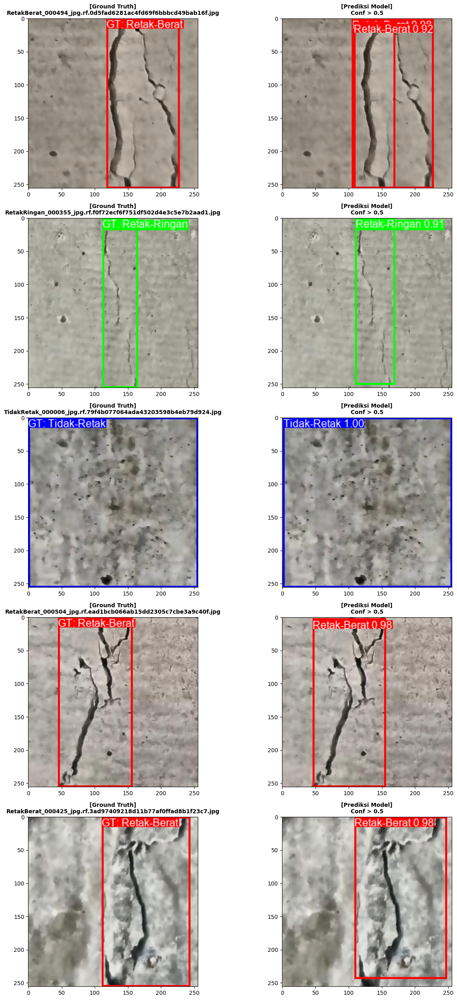

Gambar perbandingan tersimpan di: Result_Object_Detection\viz\side_by_side_comparison.png


In [46]:
@torch.no_grad()
def visualize_gt_vs_pred(model, dataset, device, num_images=5, score_thresh=0.5):
    # 1. Ambil sampel acak langsung dari Dataset
    indices = random.sample(range(len(dataset)), num_images)
    
    print(f"Menampilkan perbandingan {num_images} (Ground Truth) vs (Prediksi)")

    # 2. Setup Canvas
    fig, axes = plt.subplots(num_images, 2, figsize=(14, 5 * num_images))

    if num_images == 1:
        axes = np.array([axes])

    model.eval()

    # 3. Setup Font
    try:
        font = ImageFont.truetype("arial.ttf", 16)
    except IOError:
        font = ImageFont.load_default()

    for i, idx in enumerate(indices):
        # Load Data
        img_tensor, target = dataset[idx]
        
        # Ambil Nama File
        img_id = target["image_id"].item()
        img_info = dataset.coco.loadImgs(img_id)[0]
        file_name = img_info["file_name"]

        # Convert ke PIL
        img_pil = F.to_pil_image(img_tensor.cpu())

        # KOLOM KIRI: GROUND TRUTH
        gt_img = img_pil.copy()
        draw_gt = ImageDraw.Draw(gt_img)
        
        for box, label in zip(target["boxes"], target["labels"]):
            x1, y1, x2, y2 = box.tolist()
            cat_id = int(label.item())
            
            # Warna & Nama
            color = CLASS_COLORS.get(cat_id, (0, 255, 0)) # Pakai warna kelas
            name = FINAL_ID_TO_NAME.get(cat_id, str(cat_id))
            text = f"GT: {name}"
            
            # Gambar Box Tebal
            draw_gt.rectangle([x1, y1, x2, y2], outline=color, width=3)
            
            # Background Text
            bbox = draw_gt.textbbox((x1, y1), text, font=font)
            draw_gt.rectangle(bbox, fill=color)
            draw_gt.text((x1, y1), text, fill="white", font=font)

        # KOLOM KANAN: PREDIKSI MODEL
        # Inference
        output = model([img_tensor.to(device)])[0]
        
        pred_img = img_pil.copy()
        draw_pred = ImageDraw.Draw(pred_img)
        
        boxes = output["boxes"].cpu()
        labels = output["labels"].cpu()
        scores = output["scores"].cpu()

        # Filter Threshold
        keep = scores >= score_thresh
        
        for box, label, score in zip(boxes[keep], labels[keep], scores[keep]):
            x1, y1, x2, y2 = box.tolist()
            cat_id = int(label.item())
            
            color = CLASS_COLORS.get(cat_id, (255, 0, 0))
            name = FINAL_ID_TO_NAME.get(cat_id, str(cat_id))
            text = f"{name} {score:.2f}"
            
            draw_pred.rectangle([x1, y1, x2, y2], outline=color, width=3)
            
            bbox = draw_pred.textbbox((x1, y1), text, font=font)
            draw_pred.rectangle(bbox, fill=color)
            draw_pred.text((x1, y1), text, fill="white", font=font)

        # PLOTTING
        # Plot GT
        axes[i, 0].imshow(gt_img)
        axes[i, 0].set_title(f"[Ground Truth]\n{os.path.basename(file_name)}", fontsize=10, fontweight='bold')
        axes[i, 0].axis("on")

        # Plot Prediksi
        axes[i, 1].imshow(pred_img)
        axes[i, 1].set_title(f"[Prediksi Model]\nConf > {score_thresh}", fontsize=10, fontweight='bold')
        axes[i, 1].axis("on")

    plt.tight_layout()
    
    # Simpan
    save_path = OUT_DIR / "viz" / "side_by_side_comparison.png"
    save_path.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(save_path, dpi=150)
    
    plt.show()
    print(f"Gambar perbandingan tersimpan di: {save_path}")

# Gunakan 'test_ds' (Dataset)
visualize_gt_vs_pred(model_final, test_ds, DEVICE, num_images=5, score_thresh=0.5)

Inference Otomatis Simpan Hasil Overlay

In [47]:
import glob

INPUT_DIR = Path("Tanggul/eksperimen/dataset/images") 
OUTPUT_DIR = OUT_DIR / "results_detection_rcnn"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Threshold Confidence
CONF_THRESHOLD = 0.5 

try:
    # Cek Model
    if 'model_final' not in locals():
        raise NameError("model_final belum dimuat!")

    print(f"Mencari gambar di folder input: {INPUT_DIR}")

    # Cari semua file gambar (jpg, jpeg, png)
    extensions = ['*.jpg', '*.jpeg', '*.png', '*.JPG', '*.PNG']
    image_paths = []
    for ext in extensions:
        image_paths.extend(list(INPUT_DIR.glob(ext)))
    
    image_paths.sort()
    JUMLAH_GAMBAR = len(image_paths)

    if JUMLAH_GAMBAR == 0:
        print(f"Tidak ada gambar ditemukan di {INPUT_DIR}")
    else:
        print(f"Ditemukan {JUMLAH_GAMBAR} file gambar.")
        print(f"Hasil akan disimpan di: {OUTPUT_DIR}")

    # Setup Font
    try:
        font = ImageFont.truetype("arial.ttf", 14)
    except IOError:
        font = ImageFont.load_default()

    model_final.eval()

    # 2. LOOP PROSES
    for i, image_path in enumerate(tqdm(image_paths, desc="Processing Images")):
        try:
            # A. Muat Gambar (Pakai PIL agar aman RGB)
            img_pil = Image.open(image_path).convert("RGB")
            
            # B. PENTING: RESIZE KE UKURAN TRAINING (256x256)
            img_resized = img_pil.resize((TARGET_SIZE[1], TARGET_SIZE[0]), Image.BILINEAR)
            
            # C. Inference
            img_tensor = F.to_tensor(img_resized).unsqueeze(0).to(device)
            
            with torch.no_grad():
                output = model_final(img_tensor)[0]

            # D. Visualisasi
            draw = ImageDraw.Draw(img_resized)
            
            boxes = output["boxes"].cpu()
            labels = output["labels"].cpu()
            scores = output["scores"].cpu()

            # Filter Score
            keep = scores >= CONF_THRESHOLD
            
            for box, label, score in zip(boxes[keep], labels[keep], scores[keep]):
                x1, y1, x2, y2 = box.tolist()
                cat_id = int(label.item())
                
                # Ambil Nama & Warna dari Config Global
                color = CLASS_COLORS.get(cat_id, (255, 0, 0)) 
                class_name = FINAL_ID_TO_NAME.get(cat_id, str(cat_id))
                text = f"{class_name} {score:.2f}"
                
                # Gambar Box
                draw.rectangle([x1, y1, x2, y2], outline=color, width=3)
                
                # Gambar Background Teks
                try:
                    bbox = draw.textbbox((x1, y1), text, font=font)
                except:
                    w_t, h_t = draw.textsize(text, font=font)
                    bbox = (x1, y1, x1 + w_t, y1 + h_t)
                    
                draw.rectangle(bbox, fill=color)
                draw.text((x1, y1), text, fill="white", font=font)

            # E. Simpan Hasil
            output_filename = f"deteksi_{image_path.name}"
            save_path = OUTPUT_DIR / output_filename
            
            # Simpan gambar yang sudah di-resize dan digambar kotak
            img_resized.save(save_path)

        except Exception as e:
            print(f"\nGagal memproses {image_path.name}: {e}")

    print(f"\nInference Selesai! Cek folder: {OUTPUT_DIR}")

except NameError as ne:
    print(f"\nFATAL: {ne}")
except Exception as ex:
    print(f"\nTerjadi error sistem: {ex}")

Mencari gambar di folder input: Tanggul\eksperimen\dataset\images
Ditemukan 810 file gambar.
Hasil akan disimpan di: Result_Object_Detection\results_detection_rcnn


Processing Images: 100%|█████████████████████████████████████████████████████████████| 810/810 [05:34<00:00,  2.42it/s]


Inference Selesai! Cek folder: Result_Object_Detection\results_detection_rcnn


Visualisasi Sampel Hasil Inference

Memuat hasil deteksi dari: Result_Object_Detection\results_detection_rcnn
Ditemukan 405 hasil. Menampilkan 9 sampel...


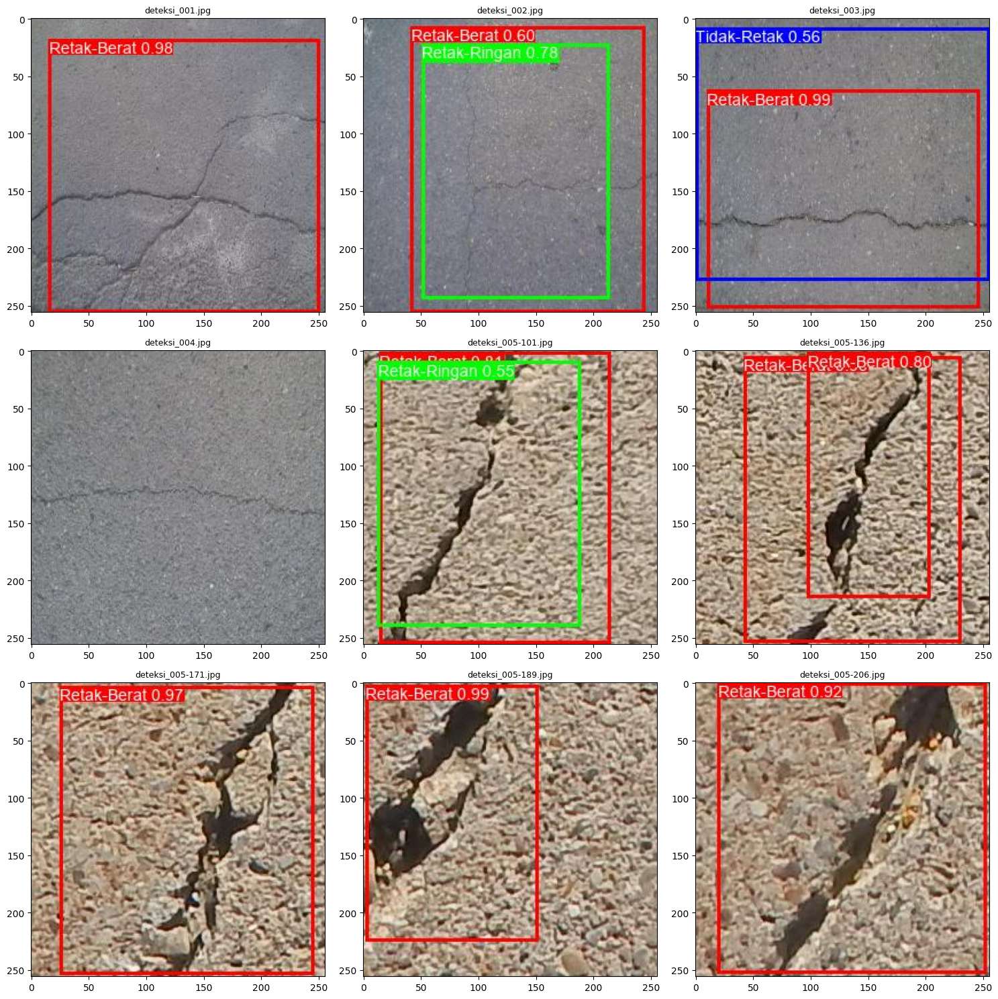

In [48]:
RESULT_DIR = OUT_DIR / "results_detection_rcnn"
NUM_TO_SHOW = 9  # Jumlah maksimal gambar yang ingin ditampilkan

print(f"Memuat hasil deteksi dari: {RESULT_DIR}")

# 1. Cari File Hasil (Pola: deteksi_*)
image_paths = sorted(list(RESULT_DIR.glob("deteksi_*")))

# Filter hanya file gambar valid (antisipasi file lain)
valid_exts = {'.jpg', '.jpeg', '.png', '.JPG', '.PNG'}
image_paths = [p for p in image_paths if p.suffix in valid_exts]

# 2. Logika Visualisasi
if not image_paths:
    print(f"Tidak ada file dengan prefix 'deteksi_' ditemukan di {RESULT_DIR}")
    print("Pastikan cell 'Inference Otomatis' sebelumnya sudah dijalankan sukses.")
else:
    count = len(image_paths)
    display_count = min(NUM_TO_SHOW, count)
    print(f"Ditemukan {count} hasil. Menampilkan {display_count} sampel...")

    # Ambil sampel (bisa acak atau urut)
    # images_to_show = random.sample(image_paths, display_count) 
    images_to_show = image_paths[:display_count] 

    # Hitung Baris yang dibutuhkan (3 Kolom)
    cols = 3
    rows = int(np.ceil(display_count / cols))

    # Setup Canvas
    fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
    
    # Ratakan axes menjadi 1D array agar mudah di-loop
    if isinstance(axes, np.ndarray):
        axes = axes.flatten()
    else:
        axes = np.array([axes])

    # 3. Loop Tampilkan Gambar
    for i in range(len(axes)):
        ax = axes[i]
        
        if i < display_count:
            # Load Gambar
            img_path = images_to_show[i]
            try:
                img = Image.open(img_path)
                
                ax.imshow(img)
                ax.set_title(img_path.name, fontsize=9)
                ax.axis("on")
            except Exception as e:
                print(f"Gagal load {img_path}: {e}")
        else:
            ax.axis("on")

    plt.tight_layout()
    plt.show()